# Práctico: comparar detectores sobre un servicio más difícil (estudiantes)

Las clases 9–11 cubrieron cuatro familias de detectores. Acá las enfrentamos **al mismo dataset**, más cargado que el plano $(N_t,R_t)$ de las clases 10 y 11.

$$
\text{logs}\longrightarrow\text{ventanas}\longrightarrow\mathbf x_t
\longrightarrow s(\mathbf x_t)\longrightarrow h_\tau(\mathbf x_t).
$$

## Detectores

| Método | Vista | Pregunta |
|---|---|---|
| k-sigma (z-score) | univariado | ¿$x$ está a más de $k$ desvíos de $\mu$? |
| MAD (z-score robusto) | univariado | ¿$x$ está lejos de la mediana, con escala $1.4826\,\mathrm{MAD}$? |
| Isolation Forest | multivariado | ¿$x$ se aísla rápido con cortes aleatorios? |
| One-Class SVM (RBF) | multivariado | ¿$x$ queda fuera de la frontera del volumen normal? |

## Lo que cambia respecto de las clases 10 y 11

El servicio sigue siendo el mismo tipo de historia (requests, errores, ahora también latencia y CPU). La nube normal sigue siendo un **manifold**: las cuatro métricas se mueven juntas con la carga. Encima hay:

1. anomalías fáciles (un eje se dispara);
2. combinaciones raras (ningún eje es extremo, el *par* o el *cuádruple* sí);
3. trampas operativas (pico de carga y un job batch que son **legítimos**);
4. una degradación lenta y tres spikes de error rate (duelen al k-sigma, menos al MAD).

`kind` e `is_anomaly` están para **evaluar después**. No los usen para entrenar.


## Cómo trabajar este cuaderno

1. Ejecuten todo hasta el final de la sección 3 (datos + exploración + protocolo).
2. Completen los `TODO` de las secciones 4 a 7. Cada una pide un *score* y una *flag*.
3. Recién ahí corran la comparación. Si una bandera no existe, esa sección va a fallar.
4. Respondan las preguntas del cierre con evidencia de las tablas y los gráficos, no de memoria.

Nombres de columnas que el cuaderno espera:

- `flag_ksigma_error`, `flag_ksigma_lat`
- `flag_mad_error`, `flag_mad_lat`
- `flag_if`, `flag_ocsvm`


In [34]:
from __future__ import annotations

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.ensemble import IsolationForest
from sklearn.metrics import precision_recall_fscore_support
from sklearn.preprocessing import StandardScaler
from sklearn.svm import OneClassSVM

SEED = 42
rng = np.random.default_rng(SEED)

plt.style.use("seaborn-v0_8-whitegrid")
BLUE, ORANGE, GREEN, GRAY, PURPLE, TEAL = "#183B66", "#E76F51", "#2A9D8F", "#5F6B76", "#8E5BA6", "#00A6A6"
plt.rcParams["figure.figsize"] = (9, 4.6)
plt.rcParams["axes.titlesize"] = 12

KIND_COLORS = {
    "normal": BLUE,
    "batch": TEAL,
    "pico_carga": GREEN,
    "spike_error": "#C9A227",
    "incidente_5xx": ORANGE,
    "timeouts": PURPLE,
    "latencia_silenciosa": "#D62828",
    "combo_sutil": "#9B2226",
    "degradacion": "#BC6C25",
    "cpu_latencia": "#6A4C93",
    "micro_burst": "#F4A261",
}

print(f"Semilla: {SEED}")


Semilla: 42


## 1. Dataset sintético

Cada fila es **un minuto** de un servicio de checkout. Features:

- $N_t$ `requests` — volumen,
- $R_t$ `error_rate` — fracción de ERROR,
- `latency_ms` — latencia media de la ventana,
- `cpu_pct` — CPU del pod.

La relación normal es aproximadamente lineal con la carga. Lo raro no es “un número grande”: es **salirse de esa relación**, o un eje que se rompe mientras los otros no.


In [35]:
minutes = pd.date_range("2026-06-03 08:00", periods=300, freq="min")
n = len(minutes)
hour = minutes.hour.to_numpy() + minutes.minute.to_numpy() / 60.0
# Misma familia de trafico que clases 10-11: rampa matinal, no un salto de regimen.
traffic = 70 + 90 * np.clip(np.sin((hour - 8) * np.pi / 6), 0, None)
requests = np.maximum(25, np.rint(traffic + rng.normal(0, 8, n))).astype(float)
error_rate = np.clip(0.0035 + 0.000045 * requests + rng.normal(0, 0.0010, n), 0.0008, None)
latency_ms = np.clip(68 + 0.22 * requests + rng.normal(0, 6.5, n), 40, None)
cpu_pct = np.clip(16 + 0.17 * requests + rng.normal(0, 4.0, n), 8, None)

kind = np.full(n, "normal", dtype=object)


def window(start, end):
    return np.asarray((minutes >= start) & (minutes < end))


# Job batch legitimo: CPU alto, el resto sigue el manifold. NO es incidente.
for start in ("2026-06-03 08:25", "2026-06-03 09:12", "2026-06-03 10:30", "2026-06-03 11:42"):
    m = window(start, pd.Timestamp(start) + pd.Timedelta(minutes=5))
    kind[m] = "batch"
    cpu_pct[m] = rng.uniform(70, 84, m.sum())
    requests[m] = np.maximum(25, requests[m] - rng.integers(8, 14, m.sum()))
    error_rate[m] = np.clip(0.0035 + 0.000045 * requests[m] + rng.normal(0, 0.0008, m.sum()), 0.0008, None)
    latency_ms[m] = np.clip(68 + 0.22 * requests[m] + rng.normal(0, 5.0, m.sum()), 40, None)

# Spikes univariados de error_rate: contaminan media y sigma, casi no mueven al MAD.
for ts in ("2026-06-03 08:18", "2026-06-03 08:41", "2026-06-03 09:05"):
    m = window(ts, pd.Timestamp(ts) + pd.Timedelta(minutes=1))
    kind[m] = "spike_error"
    error_rate[m] = rng.uniform(0.021, 0.025, m.sum())

# Incidente clasico (combinacion rara): poco trafico, mucho error, latencia alta.
m = window("2026-06-03 09:50", "2026-06-03 09:58")
kind[m] = "incidente_5xx"
requests[m] = rng.integers(30, 44, m.sum())
error_rate[m] = rng.uniform(0.036, 0.048, m.sum())
latency_ms[m] = rng.uniform(210, 260, m.sum())
cpu_pct[m] = rng.uniform(28, 40, m.sum())

# Timeouts: trafico medio, error y latencia altos.
m = window("2026-06-03 09:22", "2026-06-03 09:26")
kind[m] = "timeouts"
error_rate[m] = rng.uniform(0.023, 0.028, m.sum())
latency_ms[m] = rng.uniform(175, 200, m.sum())

# Pico de carga sobre el manifold: extremo en un eje, relacion habitual.
m = window("2026-06-03 11:18", "2026-06-03 11:26")
kind[m] = "pico_carga"
requests[m] = rng.integers(165, 185, m.sum())
error_rate[m] = 0.0035 + 0.000045 * requests[m] + rng.normal(0, 0.0007, m.sum())
latency_ms[m] = 68 + 0.22 * requests[m] + rng.normal(0, 5.0, m.sum())
cpu_pct[m] = 16 + 0.17 * requests[m] + rng.normal(0, 3.5, m.sum())

# Latencia silenciosa: solo un eje se rompe.
m = window("2026-06-03 10:40", "2026-06-03 10:46")
kind[m] = "latencia_silenciosa"
latency_ms[m] = rng.uniform(195, 230, m.sum())

# Combinacion sutil: poco trafico + error alto, pero cada eje crudo queda bajo 3 MAD.
# Es un incidente_5xx atenuado: se ve en el plano, no en un histograma.
m = window("2026-06-03 10:08", "2026-06-03 10:15")
kind[m] = "combo_sutil"
requests[m] = rng.integers(50, 62, m.sum())
error_rate[m] = rng.uniform(0.0132, 0.0140, m.sum())
latency_ms[m] = rng.uniform(118, 128, m.sum())
cpu_pct[m] = 16 + 0.17 * requests[m] + rng.normal(0, 3.5, m.sum())

# Degradacion colectiva: la latencia sube de a poco. El primer minuto casi no se ve.
m = window("2026-06-03 11:50", "2026-06-03 12:08")
kind[m] = "degradacion"
ramp = np.linspace(8, 95, m.sum())
latency_ms[m] = latency_ms[m] + ramp

# Degradacion parcial: CPU y latencia, sin errores.
m = window("2026-06-03 12:22", "2026-06-03 12:27")
kind[m] = "cpu_latencia"
cpu_pct[m] = rng.uniform(78, 90, m.sum())
latency_ms[m] = rng.uniform(180, 215, m.sum())

# Micro-burst: facil para todos.
m = window("2026-06-03 12:41", "2026-06-03 12:43")
kind[m] = "micro_burst"
error_rate[m] = rng.uniform(0.055, 0.070, m.sum())
latency_ms[m] = rng.uniform(240, 280, m.sum())

anomalous_kinds = {
    "spike_error", "incidente_5xx", "timeouts", "latencia_silenciosa",
    "combo_sutil", "degradacion", "cpu_latencia", "micro_burst",
}
data = pd.DataFrame({
    "timestamp": minutes,
    "requests": requests,
    "error_rate": error_rate,
    "latency_ms": latency_ms,
    "cpu_pct": cpu_pct,
    "kind": kind,
})
data["is_anomaly"] = data["kind"].isin(anomalous_kinds)
FEATURES = ["requests", "error_rate", "latency_ms", "cpu_pct"]

print(f"Ventanas: {len(data)}  |  anomalías reales: {int(data.is_anomaly.sum())} ({100 * data.is_anomaly.mean():.1f}%)")
display(data.groupby("kind")[FEATURES].agg(["count", "mean"]).round(3))


Ventanas: 300  |  anomalías reales: 53 (17.7%)


requests          error_rate        latency_ms           \
                       count     mean      count   mean      count     mean   
kind                                                                          
batch                     20  121.750         20  0.009         20   92.201   
combo_sutil                7   54.571          7  0.014          7  122.551   
cpu_latencia               5  139.000          5  0.010          5  205.789   
degradacion               18  144.722         18  0.010         18  154.781   
incidente_5xx              8   36.750          8  0.042          8  235.876   
latencia_silenciosa        6  158.333          6  0.010          6  213.073   
micro_burst                2  123.500          2  0.063          2  277.415   
normal                   219  131.137        219  0.009        219   96.067   
pico_carga                 8  173.875          8  0.012          8  104.374   
spike_error                3  107.333          3  0.023          3   88.102   
timeouts                   4  127.250          4  0.025          4  191.117   

                    cpu_pct          
                      count    mean  
kind                                 
batch                    20  75.925  
combo_sutil               7  24.982  
cpu_latencia              5  86.313  
degradacion              18  40.230  
incidente_5xx             8  36.217  
latencia_silenciosa       6  43.764  
micro_burst               2  37.104  
normal                  219  38.424  
pico_carga                8  46.033  
spike_error               3  35.427  
timeouts                  4  39.604

### Detalle de la tabla de datos

Las 53 anomalías se reparten en varios tipos; batch y pico_carga son legítimos. Por eso un valor extremo no basta para definir un incidente: importa la relación entre carga, error, latencia y CPU. Ajustar sobre toda la serie expone a los detectores a esta mezcla.


## 2. Exploración

Primero las series. Después, tres planos. El pico de carga debería verse *al extremo de la nube*; el incidente_5xx, *afuera*; el batch, *arriba en CPU* con requests normales.


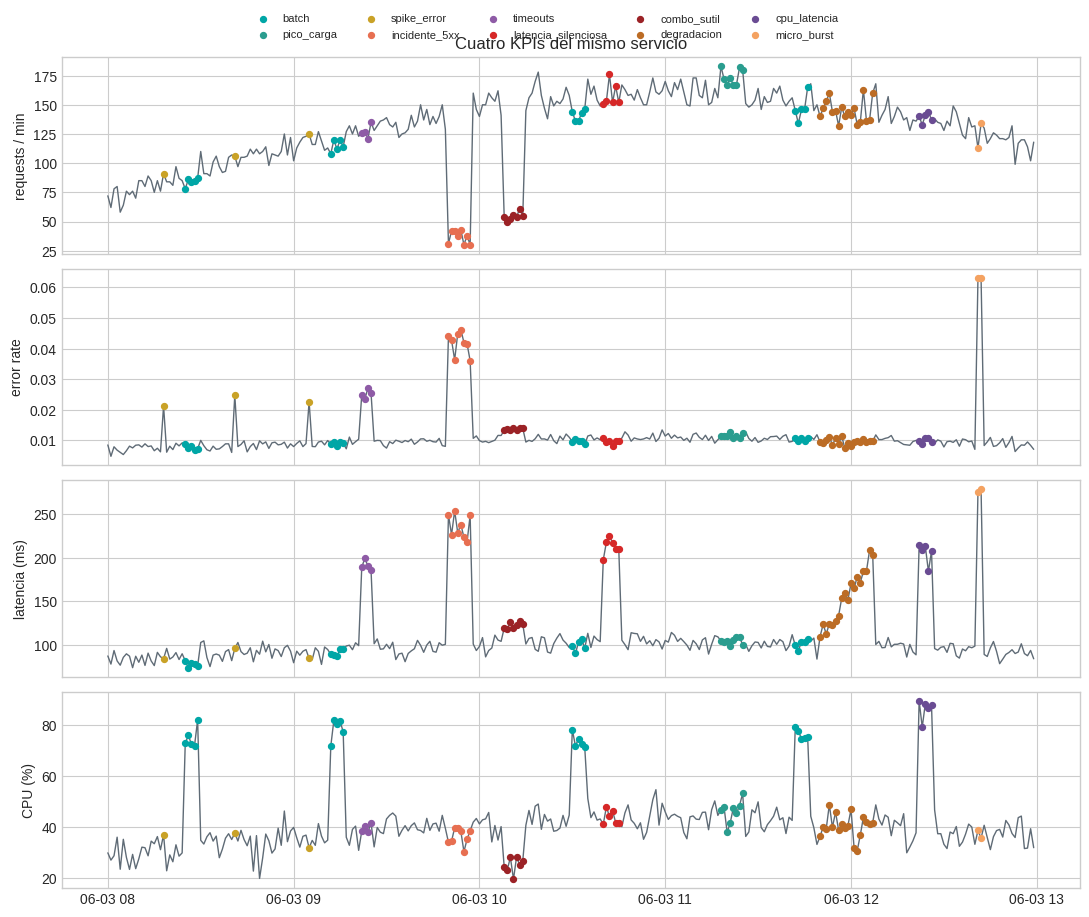

In [36]:
fig, axes = plt.subplots(4, 1, figsize=(11, 9), sharex=True)
series = [("requests", "requests / min"), ("error_rate", "error rate"), ("latency_ms", "latencia (ms)"), ("cpu_pct", "CPU (%)")]
for ax, (col, ylabel) in zip(axes, series):
    ax.plot(data["timestamp"], data[col], color=GRAY, lw=1.0)
    for name, color in KIND_COLORS.items():
        if name == "normal":
            continue
        mask = data["kind"].eq(name)
        ax.scatter(data.loc[mask, "timestamp"], data.loc[mask, col], c=color, s=18, zorder=3, label=name)
    ax.set_ylabel(ylabel)
axes[0].set_title("Cuatro KPIs del mismo servicio")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=5, bbox_to_anchor=(0.5, 1.02), fontsize=8)
plt.tight_layout()
plt.show()


### Lectura de las series

Los incidentes grandes elevan error o latencia de forma abrupta; la degradación sube de manera progresiva. El batch eleva CPU sin una falla equivalente en error o latencia. Un umbral demasiado bajo confundirá parte de esta actividad legítima con un incidente.


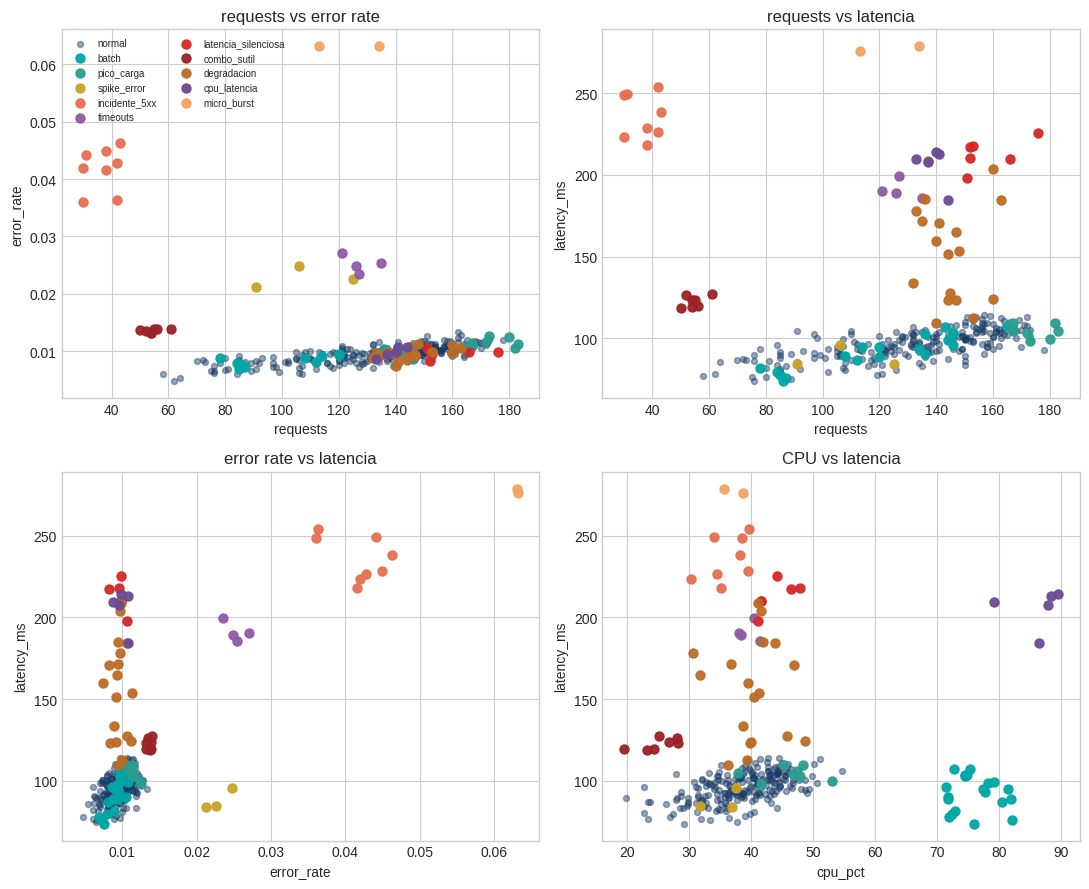

In [37]:
planes = [
    ("requests", "error_rate", "requests vs error rate"),
    ("requests", "latency_ms", "requests vs latencia"),
    ("error_rate", "latency_ms", "error rate vs latencia"),
    ("cpu_pct", "latency_ms", "CPU vs latencia"),
]
fig, axes = plt.subplots(2, 2, figsize=(11, 9))
for ax, (a, b, title) in zip(axes.ravel(), planes):
    for name, color in KIND_COLORS.items():
        mask = data["kind"].eq(name)
        ax.scatter(
            data.loc[mask, a], data.loc[mask, b],
            c=color, s=18 if name == "normal" else 42,
            alpha=0.45 if name == "normal" else 0.95,
            label=name, zorder=2 if name == "normal" else 3,
        )
    ax.set_xlabel(a)
    ax.set_ylabel(b)
    ax.set_title(title)
axes[0, 0].legend(loc="upper left", fontsize=7, ncol=2)
plt.tight_layout()
plt.show()


### Relaciones entre métricas

La nube normal acompaña el aumento de carga; el incidente_5xx combina pocas requests con mucho error y latencia. Combo_sutil se distingue mejor como combinación que en un solo eje. Los modelos multivariados pueden reconocer estas relaciones, pero no saben por sí solos que el batch está autorizado.


## 3. Protocolo de entrenamiento

Igual que Isolation Forest en la clase 10: **no hay etiquetas para aprender**. Estimamos todo sobre las 300 ventanas.

- Univariados: $\mu,\sigma$ y mediana/MAD se estiman sobre **toda** la serie. La muestra está contaminada (incidentes, spikes). Eso es el punto: k-sigma se deja llevar, MAD no.
- Isolation Forest y One-Class SVM se entrenan sobre las cuatro features **escaladas**, también sin `kind`.
- `contamination=0.10` y `nu=0.10` son un presupuesto de alertas (~30 minutos), no la tasa verdadera (~17%).
- `pico_carga` y `batch` están marcados como *no anómalos*: son trampas. Si un detector los enciende, es un falso positivo con historia operativa.


In [38]:
print("Minutos por kind:")
display(data["kind"].value_counts().rename("n").to_frame())

scaler = StandardScaler().fit(data[FEATURES])
X_all = scaler.transform(data[FEATURES])
print("Medias del scaler:", dict(zip(FEATURES, scaler.mean_.round(3))))
print("Escalas del scaler:", dict(zip(FEATURES, scaler.scale_.round(3))))


Minutos por kind:


,n
kind,
normal,219
batch,20
degradacion,18
pico_carga,8
incidente_5xx,8
combo_sutil,7
latencia_silenciosa,6
cpu_latencia,5
timeouts,4


Medias del scaler: {'requests': np.float64(128.497), 'error_rate': np.float64(0.011), 'latency_ms': np.float64(110.465), 'cpu_pct': np.float64(41.745)}
Escalas del scaler: {'requests': np.float64(32.487), 'error_rate': np.float64(0.007), 'latency_ms': np.float64(38.48), 'cpu_pct': np.float64(12.56)}


## 4. k-sigma (univariado)

Sobre una serie $x_1,\dots,x_n$ (acá, las 300 ventanas):

$$
\hat\mu=\bar x,\qquad
\hat\sigma=\sqrt{\frac1{n-1}\sum_i(x_i-\hat\mu)^2},\qquad
s_k(x)=\left|\frac{x-\hat\mu}{\hat\sigma}\right|.
$$

Alerta si $s_k(x)>k$. Usamos $k=3$. Aplíquenlo a `error_rate` y a `latency_ms`.

Ojo: los tres `spike_error` y los incidentes grandes están *dentro* de la muestra. Inflan $\hat\sigma$ del error rate. Eso es parte del ejercicio.


In [39]:
def k_sigma_fit(series: pd.Series):
    # Devuelve (mu, sigma) estimados sobre la serie, con ddof=1.
    # TODO: mu = ...; sigma = ...
    mu = series.mean()
    sigma = series.std(ddof=1)
    return mu, sigma


def k_sigma_score(series: pd.Series, mu: float, sigma: float):
    # Score |x - mu| / sigma, alineado con el indice de series.
    # TODO: return ...
    if sigma == 0:
        return pd.Series(np.where(series.eq(mu), 0.0, np.inf), index=series.index)
    return (series - mu).abs() / sigma


K = 3.0
mu_err, sig_err = k_sigma_fit(data["error_rate"])
mu_lat, sig_lat = k_sigma_fit(data["latency_ms"])
data["score_ksigma_error"] = k_sigma_score(data["error_rate"], mu_err, sig_err)
data["score_ksigma_lat"] = k_sigma_score(data["latency_ms"], mu_lat, sig_lat)
data["flag_ksigma_error"] = data["score_ksigma_error"] > K
data["flag_ksigma_lat"] = data["score_ksigma_lat"] > K

print(f"error_rate  μ={mu_err:.4f}  σ={sig_err:.4f}  umbral 3σ={mu_err + 3 * sig_err:.4f}")
print(f"latency_ms  μ={mu_lat:.2f}  σ={sig_lat:.2f}  umbral 3σ={mu_lat + 3 * sig_lat:.1f}")
print("Alertas k-sigma error:", int(data.flag_ksigma_error.sum()), "| latencia:", int(data.flag_ksigma_lat.sum()))


error_rate  μ=0.0112  σ=0.0072  umbral 3σ=0.0328
latency_ms  μ=110.47  σ=38.54  umbral 3σ=226.1
Alertas k-sigma error: 10 | latencia: 8


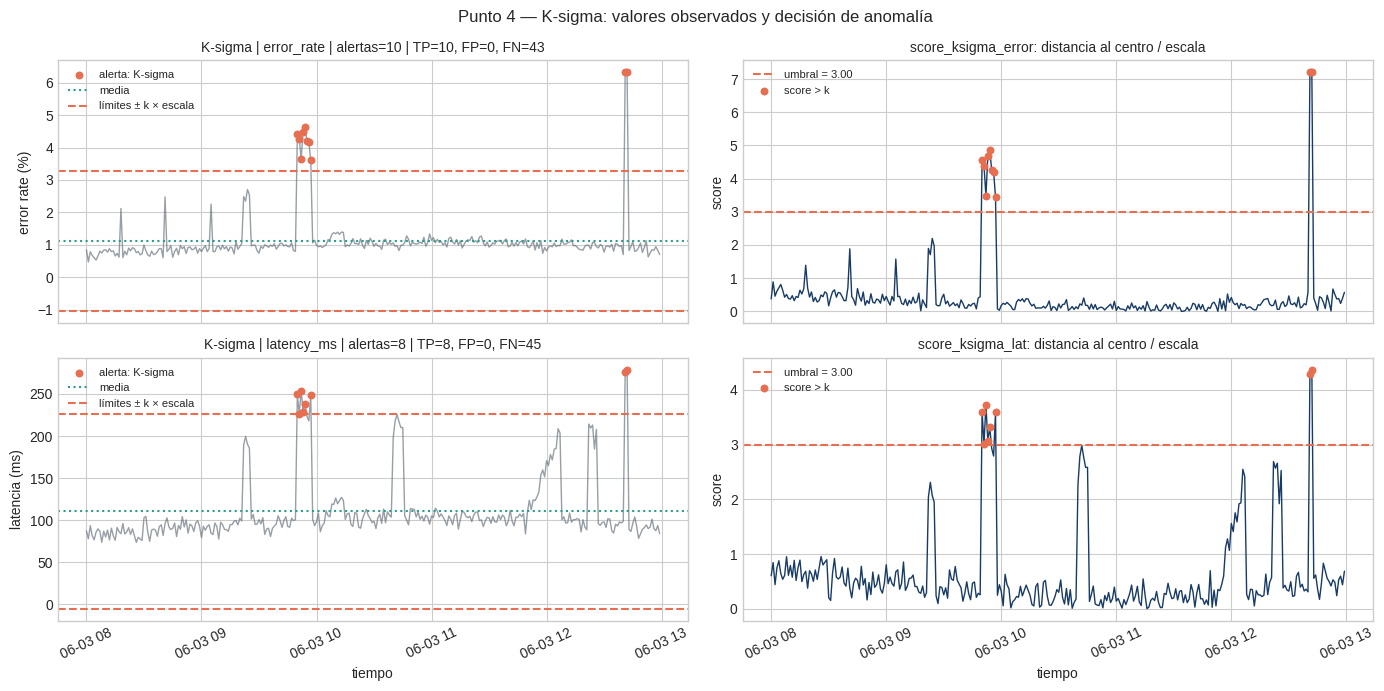

In [40]:
fig_punto4, axes = plt.subplots(2, 2, figsize=(14, 7), sharex=True)
methods = [
    ("error_rate", "score_ksigma_error", "flag_ksigma_error", mu_err, sig_err, 100, "error rate (%)"),
    ("latency_ms", "score_ksigma_lat", "flag_ksigma_lat", mu_lat, sig_lat, 1, "latencia (ms)"),
]

for (ax_serie, ax_score), (feature, score_col, flag_col, centro, escala, factor, ylabel) in zip(axes, methods):
    flagged = data[flag_col]
    tp = int((flagged & data["is_anomaly"]).sum())
    fp = int((flagged & ~data["is_anomaly"]).sum())
    fn = int((~flagged & data["is_anomaly"]).sum())

    ax_serie.plot(data["timestamp"], factor * data[feature], color=GRAY, alpha=0.65, linewidth=1)
    ax_serie.scatter(
        data.loc[flagged, "timestamp"], factor * data.loc[flagged, feature],
        color=ORANGE, s=22, label="alerta: K-sigma", zorder=3,
    )
    ax_serie.axhline(factor * centro, color=GREEN, linestyle=":", label="media")
    ax_serie.axhline(factor * (centro + K * escala), color=ORANGE, linestyle="--", label="límites ± k × escala")
    ax_serie.axhline(factor * (centro - K * escala), color=ORANGE, linestyle="--")
    ax_serie.set_ylabel(ylabel)
    ax_serie.set_title(f"K-sigma | {feature} | alertas={int(flagged.sum())} | TP={tp}, FP={fp}, FN={fn}", fontsize=10)
    ax_serie.legend(loc="upper left", fontsize=8)

    ax_score.plot(data["timestamp"], data[score_col], color=BLUE, linewidth=1)
    ax_score.axhline(K, color=ORANGE, linestyle="--", label=f"umbral = {K:.2f}")
    ax_score.scatter(
        data.loc[flagged, "timestamp"], data.loc[flagged, score_col],
        color=ORANGE, s=22, label="score > k", zorder=3,
    )
    ax_score.set_ylabel("score")
    ax_score.set_title(f"{score_col}: distancia al centro / escala", fontsize=10)
    ax_score.legend(loc="upper left", fontsize=8)

for ax in axes[-1]:
    ax.set_xlabel("tiempo")
    ax.tick_params(axis="x", rotation=25)
fig_punto4.suptitle("Punto 4 — K-sigma: valores observados y decisión de anomalía")
plt.tight_layout()
plt.show()


### Lectura de la gráfica de K-sigma

La izquierda muestra el KPI y sus límites; la derecha, su score frente a **k=3**. Las alertas naranjas se concentran en los incidentes más extremos: el desvío inflado deja fuera anomalías moderadas. **Subir k** ensancha los límites y omite más casos; **bajarlo** detecta más minutos, con riesgo de alertar fluctuaciones legítimas.


### Análisis del resultado de K-sigma

Con k=3, error detecta **10/53** anomalías y latencia **8/53**, sin falsas alertas. La latencia silenciosa queda sin detectar porque el desvío global es grande. Bajar k reduce ese ocultamiento, pero no corrige la escala contaminada; subirlo vuelve el detector todavía menos sensible.


## 5. MAD / z-score robusto (univariado)

$$
\widetilde x=\operatorname{median}(x_i),\qquad
\operatorname{MAD}=\operatorname{median}(|x_i-\widetilde x|),\qquad
\widehat\sigma_{\mathrm{MAD}}=1.4826\,\operatorname{MAD}.
$$

$$
s_r(x)=\left|\frac{x-\widetilde x}{\widehat\sigma_{\mathrm{MAD}}}\right|.
$$

Alerta si $s_r(x)>k$, otra vez $k=3$. La constante $1.4826$ hace que, si $x$ fuera normal, $\widehat\sigma_{\mathrm{MAD}}$ estime $\sigma$. Mediana y MAD toleran hasta casi un $50\%$ de contaminación; los tres spikes no deberían desplazarlos.


In [41]:
def mad_fit(series: pd.Series):
    # Devuelve (mediana, MAD, escala=1.4826*MAD).
    # TODO
    med = series.median()
    mad = (series - med).abs().median()
    return med, mad, 1.4826 * mad


def mad_score(series: pd.Series, med: float, scale: float):
    # Score |x - mediana| / escala. Si escala==0, devolver 0 en la mediana e inf fuera.
    # TODO
    if scale == 0:
        return pd.Series(np.where(series.eq(med), 0.0, np.inf), index=series.index)
    return (series - med).abs() / scale


med_err, mad_err, scale_err = mad_fit(data["error_rate"])
med_lat, mad_lat, scale_lat = mad_fit(data["latency_ms"])
data["score_mad_error"] = mad_score(data["error_rate"], med_err, scale_err)
data["score_mad_lat"] = mad_score(data["latency_ms"], med_lat, scale_lat)
data["flag_mad_error"] = data["score_mad_error"] > K
data["flag_mad_lat"] = data["score_mad_lat"] > K

print(f"error_rate  mediana={med_err:.4f}  MAD={mad_err:.4f}  escala={scale_err:.4f}  (σ k-sigma={sig_err:.4f})")
print(f"latency_ms  mediana={med_lat:.2f}  MAD={mad_lat:.2f}  escala={scale_lat:.2f}  (σ k-sigma={sig_lat:.2f})")
print("Alertas MAD error:", int(data.flag_mad_error.sum()), "| latencia:", int(data.flag_mad_lat.sum()))


error_rate  mediana=0.0097  MAD=0.0010  escala=0.0016  (σ k-sigma=0.0072)
latency_ms  mediana=99.22  MAD=7.84  escala=11.62  (σ k-sigma=38.54)
Alertas MAD error: 18 | latencia: 36


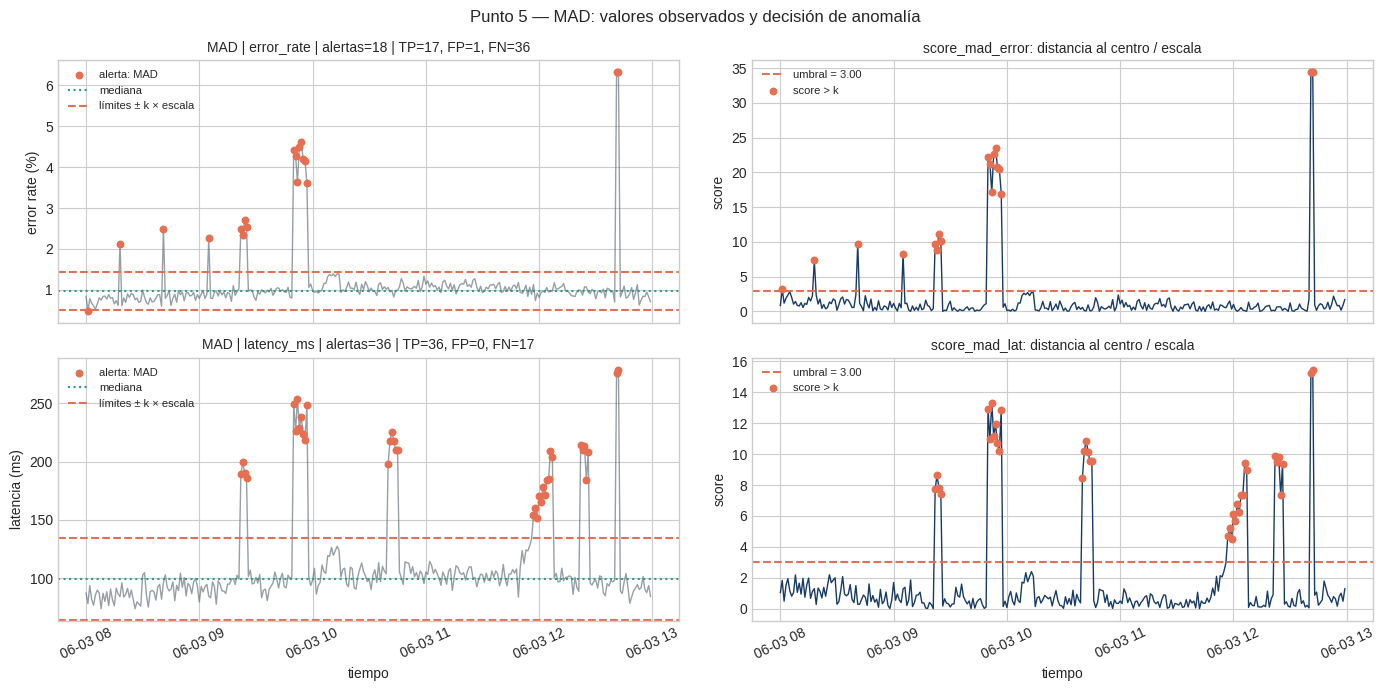

In [42]:
fig_punto5, axes = plt.subplots(2, 2, figsize=(14, 7), sharex=True)
methods = [
    ("error_rate", "score_mad_error", "flag_mad_error", med_err, scale_err, 100, "error rate (%)"),
    ("latency_ms", "score_mad_lat", "flag_mad_lat", med_lat, scale_lat, 1, "latencia (ms)"),
]

for (ax_serie, ax_score), (feature, score_col, flag_col, centro, escala, factor, ylabel) in zip(axes, methods):
    flagged = data[flag_col]
    tp = int((flagged & data["is_anomaly"]).sum())
    fp = int((flagged & ~data["is_anomaly"]).sum())
    fn = int((~flagged & data["is_anomaly"]).sum())

    ax_serie.plot(data["timestamp"], factor * data[feature], color=GRAY, alpha=0.65, linewidth=1)
    ax_serie.scatter(
        data.loc[flagged, "timestamp"], factor * data.loc[flagged, feature],
        color=ORANGE, s=22, label="alerta: MAD", zorder=3,
    )
    ax_serie.axhline(factor * centro, color=GREEN, linestyle=":", label="mediana")
    ax_serie.axhline(factor * (centro + K * escala), color=ORANGE, linestyle="--", label="límites ± k × escala")
    ax_serie.axhline(factor * (centro - K * escala), color=ORANGE, linestyle="--")
    ax_serie.set_ylabel(ylabel)
    ax_serie.set_title(f"MAD | {feature} | alertas={int(flagged.sum())} | TP={tp}, FP={fp}, FN={fn}", fontsize=10)
    ax_serie.legend(loc="upper left", fontsize=8)

    ax_score.plot(data["timestamp"], data[score_col], color=BLUE, linewidth=1)
    ax_score.axhline(K, color=ORANGE, linestyle="--", label=f"umbral = {K:.2f}")
    ax_score.scatter(
        data.loc[flagged, "timestamp"], data.loc[flagged, score_col],
        color=ORANGE, s=22, label="score > k", zorder=3,
    )
    ax_score.set_ylabel("score")
    ax_score.set_title(f"{score_col}: distancia al centro / escala", fontsize=10)
    ax_score.legend(loc="upper left", fontsize=8)

for ax in axes[-1]:
    ax.set_xlabel("tiempo")
    ax.tick_params(axis="x", rotation=25)
fig_punto5.suptitle("Punto 5 — MAD: valores observados y decisión de anomalía")
plt.tight_layout()
plt.show()


### Lectura de la gráfica de MAD

Los límites robustos son más estrechos que los de K-sigma: se basan en la mediana y MAD, menos afectados por extremos. Con **k=3**, latencia detecta **36/53** anomalías y las seis ventanas de latencia silenciosa. **Bajar k** incorpora desviaciones menores; **subirlo** exige desviaciones más grandes, sin cambiar los scores.


### Sensibilidad en MAD

En latencia, **k=2** detecta 45 anomalías con 4 falsos positivos; **k=3**, 36 sin falsos positivos; **k=5**, 34 sin falsos positivos. Bajar el umbral recupera incidentes, a costa de más ruido. Aumentarlo reduce alertas, pero pierde anomalías reales; no hay una mejora automática del F1.


## 6. Isolation Forest (multivariado, 4D)

Entrenen sobre `X_all` (300 ventanas ya escaladas). `contamination` es una **política** de recorte, no un diagnóstico: acá $0.10$.

Score para ranking, igual que en la clase 10:

$$
\mathrm{score}_{\mathrm{IF}}(x)=-\texttt{score\_samples}(x).
$$

Flag: `predict == -1`. Features: las cuatro.


In [43]:
# TODO: instanciar IsolationForest (n_estimators=300, max_samples=min(256, len(data)),
#       contamination=0.10, random_state=42), fit sobre X_all.
forest = IsolationForest(
    n_estimators=300, max_samples=min(256, len(data)),
    contamination=0.10, random_state=42,
)
forest.fit(X_all)

# TODO: data["score_if"] = -forest.score_samples(X_all)
data["score_if"] = -forest.score_samples(X_all)
# TODO: data["flag_if"] = forest.predict(X_all) == -1
data["flag_if"] = forest.predict(X_all) == -1

print("Alertas Isolation Forest:", int(data.flag_if.sum()) if "flag_if" in data else "pendiente")


Alertas Isolation Forest: 30


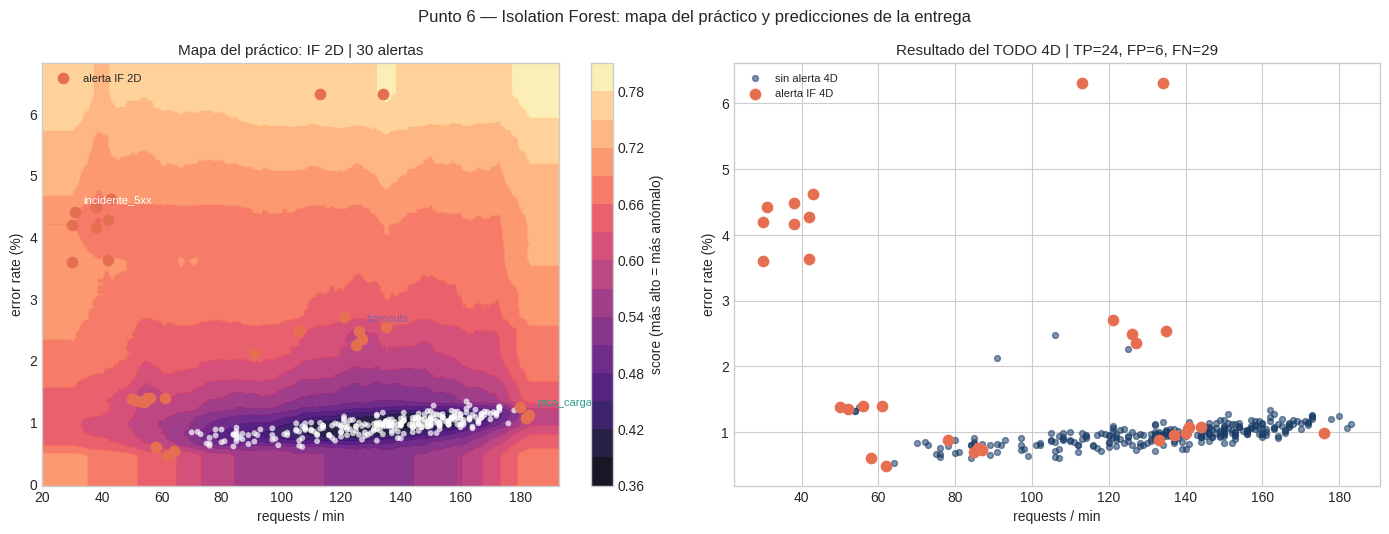

In [44]:
X_mapa6 = data[["requests", "error_rate"]].to_numpy()
forest_mapa6 = IsolationForest(
    n_estimators=300, max_samples=min(256, len(data)),
    contamination=0.10, random_state=42,
).fit(X_mapa6)
flags_mapa6 = forest_mapa6.predict(X_mapa6) == -1

xx6, yy6 = np.meshgrid(
    np.linspace(X_mapa6[:, 0].min() - 10, X_mapa6[:, 0].max() + 10, 200),
    np.linspace(X_mapa6[:, 1].min() - 0.005, X_mapa6[:, 1].max() + 0.005, 200),
)
grid6 = np.column_stack([xx6.ravel(), yy6.ravel()])
zz6 = -forest_mapa6.score_samples(grid6).reshape(xx6.shape)

fig_punto6, axes = plt.subplots(1, 2, figsize=(14, 5.4))
ax = axes[0]
contour = ax.contourf(xx6, 100 * yy6, zz6, levels=14, cmap="magma", alpha=0.92)
ax.scatter(data.loc[~flags_mapa6, "requests"], 100 * data.loc[~flags_mapa6, "error_rate"],
           c="white", s=18, alpha=0.7, edgecolors="none")
ax.scatter(data.loc[flags_mapa6, "requests"], 100 * data.loc[flags_mapa6, "error_rate"],
           c=ORANGE, s=55, label="alerta IF 2D", zorder=3)
for name, color in {"incidente_5xx": "white", "pico_carga": GREEN, "timeouts": PURPLE}.items():
    row = data.loc[data["kind"].eq(name)].iloc[0]
    ax.annotate(name, (row["requests"], 100 * row["error_rate"]),
                textcoords="offset points", xytext=(6, 6), color=color, fontsize=8)
fig_punto6.colorbar(contour, ax=ax, label="score (más alto = más anómalo)")
ax.set_xlabel("requests / min")
ax.set_ylabel("error rate (%)")
ax.set_title(f"Mapa del práctico: IF 2D | {int(flags_mapa6.sum())} alertas", fontsize=11)
ax.legend(loc="upper left", fontsize=8)
ax.grid(False)

ax = axes[1]
flags = data["flag_if"]
ax.scatter(data.loc[~flags, "requests"], 100 * data.loc[~flags, "error_rate"],
           c=BLUE, s=18, alpha=0.55, label="sin alerta 4D")
ax.scatter(data.loc[flags, "requests"], 100 * data.loc[flags, "error_rate"],
           c=ORANGE, s=55, label="alerta IF 4D", zorder=3)
tp = int((flags & data["is_anomaly"]).sum())
fp = int((flags & ~data["is_anomaly"]).sum())
fn = int((~flags & data["is_anomaly"]).sum())
ax.set_xlabel("requests / min")
ax.set_ylabel("error rate (%)")
ax.set_title(f"Resultado del TODO 4D | TP={tp}, FP={fp}, FN={fn}", fontsize=11)
ax.legend(loc="upper left", fontsize=8)
fig_punto6.suptitle("Punto 6 — Isolation Forest: mapa del práctico y predicciones de la entrega")
plt.tight_layout()
plt.show()


### Lectura del mapa de Isolation Forest

El fondo claro indica mayor rareza y el naranja señala alertas. **Izquierda: modelo 2D; derecha: predicciones reales 4D**, que también usan CPU y latencia. Subir `contamination` incorpora más puntos del mismo ranking; bajarlo conserva solo los más raros. Una CPU inusual puede explicar una alerta 4D que no destaca en este plano.


### Qué cambia en Isolation Forest

Con `contamination=0,10`, IF detecta **24 anomalías y genera 6 falsas alertas**. En las pruebas, bajarlo a 0,05 deja 15 alertas sin falsos positivos; subirlo a 0,20 produce 60, de las cuales 21 son falsas. Más árboles suelen estabilizar el score; menos árboles reducen costo. Una muestra menor o mayor cambia la referencia por árbol, sin garantizar mejor F1.


## 7. One-Class SVM RBF (multivariado, 4D)

Mismas 300 ventanas, mismas features escaladas. Kernel RBF, `nu=0.10`, `gamma="scale"`.

$$
f(x)=\sum_{i\in\mathrm{SV}}\alpha_i\,k(x_i,x)-\rho,\qquad
\mathrm{score}_{\mathrm{OCSVM}}(x)=-f(x).
$$

Flag: `predict == -1` (equivalente a $f(x)<0$).


In [45]:
# TODO: OneClassSVM(kernel="rbf", nu=0.10, gamma="scale"), fit sobre X_all.
ocsvm = OneClassSVM(kernel="rbf", nu=0.10, gamma="scale")
ocsvm.fit(X_all)

# TODO: data["score_ocsvm"] = -ocsvm.decision_function(X_all)
data["score_ocsvm"] = -ocsvm.decision_function(X_all)
# TODO: data["flag_ocsvm"] = ocsvm.predict(X_all) == -1
data["flag_ocsvm"] = ocsvm.predict(X_all) == -1

print("Alertas One-Class SVM:", int(data.flag_ocsvm.sum()) if "flag_ocsvm" in data else "pendiente")


Alertas One-Class SVM: 29


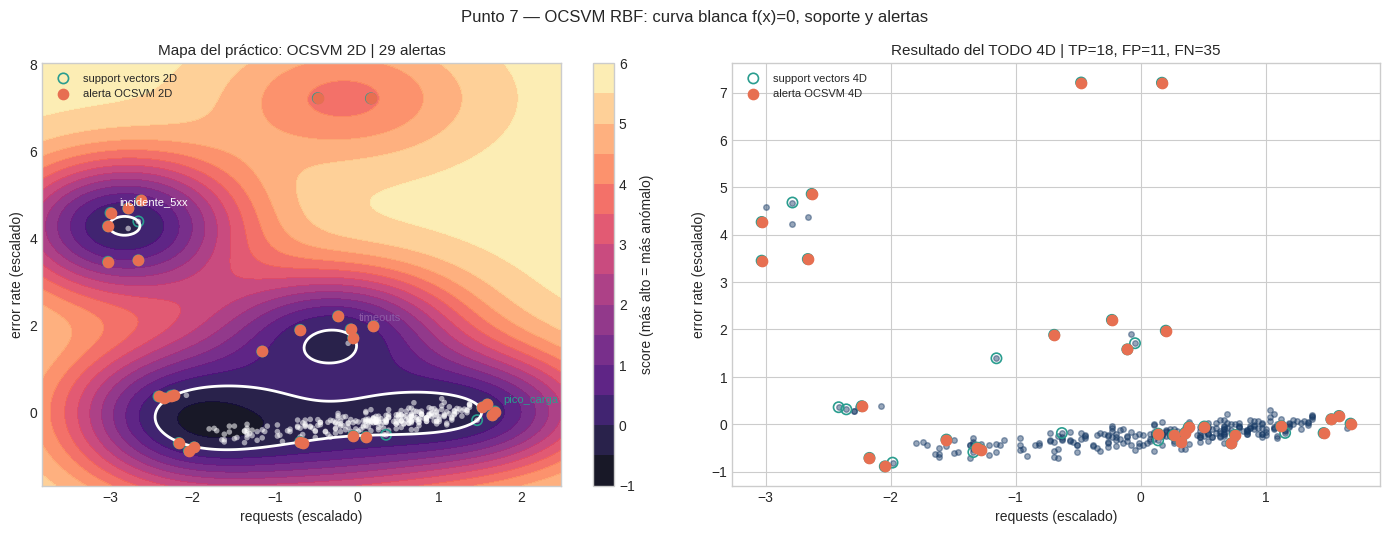

In [46]:
X_raw_mapa7 = data[["requests", "error_rate"]].to_numpy()
scaler_mapa7 = StandardScaler()
X_mapa7 = scaler_mapa7.fit_transform(X_raw_mapa7)
ocsvm_mapa7 = OneClassSVM(kernel="rbf", nu=0.10, gamma="scale").fit(X_mapa7)
flags_mapa7 = ocsvm_mapa7.predict(X_mapa7) == -1
sv_idx7 = ocsvm_mapa7.support_

xx7, yy7 = np.meshgrid(
    np.linspace(X_mapa7[:, 0].min() - 0.8, X_mapa7[:, 0].max() + 0.8, 200),
    np.linspace(X_mapa7[:, 1].min() - 0.8, X_mapa7[:, 1].max() + 0.8, 200),
)
grid7 = np.column_stack([xx7.ravel(), yy7.ravel()])
zz7 = ocsvm_mapa7.decision_function(grid7).reshape(xx7.shape)

fig_punto7, axes = plt.subplots(1, 2, figsize=(14, 5.4))
ax = axes[0]
contour = ax.contourf(xx7, yy7, -zz7, levels=14, cmap="magma", alpha=0.92)
ax.contour(xx7, yy7, zz7, levels=[0], colors="white", linewidths=2)
ax.scatter(X_mapa7[:, 0], X_mapa7[:, 1], c="white", s=16, alpha=0.55, edgecolors="none")
ax.scatter(X_mapa7[sv_idx7, 0], X_mapa7[sv_idx7, 1], facecolors="none",
           edgecolors=GREEN, s=55, lw=1.2, label="support vectors 2D")
ax.scatter(X_mapa7[flags_mapa7, 0], X_mapa7[flags_mapa7, 1],
           c=ORANGE, s=55, label="alerta OCSVM 2D", zorder=3)
for name, color in {"incidente_5xx": "white", "pico_carga": GREEN, "timeouts": PURPLE}.items():
    row_x = X_mapa7[data["kind"].eq(name).to_numpy()][0]
    ax.annotate(name, row_x, textcoords="offset points", xytext=(6, 6), color=color, fontsize=8)
fig_punto7.colorbar(contour, ax=ax, label="score (más alto = más anómalo)")
ax.set_xlabel("requests (escalado)")
ax.set_ylabel("error rate (escalado)")
ax.set_title(f"Mapa del práctico: OCSVM 2D | {int(flags_mapa7.sum())} alertas", fontsize=11)
ax.legend(loc="upper left", fontsize=8)
ax.grid(False)

ax = axes[1]
flags = data["flag_ocsvm"].to_numpy()
sv_idx4d = ocsvm.support_
ax.scatter(X_all[:, 0], X_all[:, 1], c=BLUE, s=16, alpha=0.45)
ax.scatter(X_all[sv_idx4d, 0], X_all[sv_idx4d, 1], facecolors="none",
           edgecolors=GREEN, s=55, lw=1.2, label="support vectors 4D")
ax.scatter(X_all[flags, 0], X_all[flags, 1], c=ORANGE, s=55, label="alerta OCSVM 4D", zorder=3)
real = data["is_anomaly"].to_numpy()
tp = int((flags & real).sum())
fp = int((flags & ~real).sum())
fn = int((~flags & real).sum())
ax.set_xlabel("requests (escalado)")
ax.set_ylabel("error rate (escalado)")
ax.set_title(f"Resultado del TODO 4D | TP={tp}, FP={fp}, FN={fn}", fontsize=11)
ax.legend(loc="upper left", fontsize=8)
fig_punto7.suptitle("Punto 7 — OCSVM RBF: curva blanca f(x)=0, soporte y alertas")
plt.tight_layout()
plt.show()


### Lectura de la frontera RBF

La línea blanca delimita la región aceptada del **modelo 2D**; los círculos verdes son vectores de soporte. A la derecha se proyecta el **modelo real 4D**, cuya frontera no cabe completa en este plano. **Gamma mayor** permite regiones más locales; **gamma menor** suaviza la frontera y puede absorber combinaciones anómalas. El entrenamiento contaminado puede aceptar grupos de incidentes.


### Qué cambia en OCSVM

Con `nu=0,10` y `gamma="scale"` en 4D, hay **29 alertas: 18 aciertos y 11 falsas**. Subir nu suele restringir la región aceptada; bajarlo suele aceptar más puntos, sin fijar un porcentaje exacto. Gamma=8 produjo 83 alertas, 59 falsas; gamma=0,5 produjo 28, con 8 falsas: una frontera más local no garantiza mejor detección.


## 8. Comparación

Cada fila es un `kind`. Cada columna cuenta **minutos alertados**. Un detector univariado sobre error rate no tiene por qué ver `latencia_silenciosa`. Un detector 4D no tiene por qué perdonar el `combo_sutil`. `batch` y `pico_carga` son el test de falsos positivos.


In [47]:
FLAG_COLS = {
    "k-sigma error": "flag_ksigma_error",
    "k-sigma lat": "flag_ksigma_lat",
    "MAD error": "flag_mad_error",
    "MAD lat": "flag_mad_lat",
    "Isolation Forest": "flag_if",
    "One-Class SVM": "flag_ocsvm",
}

missing = [c for c in FLAG_COLS.values() if c not in data.columns]
if missing:
    raise RuntimeError(f"Faltan columnas {missing}. Completá las secciones 4-7 antes de comparar.")

counts = data.groupby("kind")[list(FLAG_COLS.values())].sum().astype(int)
counts.columns = list(FLAG_COLS)
counts["n"] = data.groupby("kind").size()
counts["anómalo?"] = data.groupby("kind")["is_anomaly"].any()
display(counts[["n", "anómalo?", *FLAG_COLS]])

score_cols = {
    "k-sigma error": "score_ksigma_error",
    "k-sigma lat": "score_ksigma_lat",
    "MAD error": "score_mad_error",
    "MAD lat": "score_mad_lat",
    "IF": "score_if",
    "OCSVM": "score_ocsvm",
}
print("Mediana del score por kind (el ranking, no la flag):")
display(data.groupby("kind")[list(score_cols.values())].median().round(3).rename(columns={v: k for k, v in score_cols.items()}))


,n,anómalo?,k-sigma error,k-sigma lat,MAD error,MAD lat,Isolation Forest,One-Class SVM
kind,,,,,,,,
batch,20,False,0,0,0,0,4,5
combo_sutil,7,True,0,0,0,0,4,1
cpu_latencia,5,True,0,0,0,5,5,3
degradacion,18,True,0,0,0,11,0,1
incidente_5xx,8,True,8,6,8,8,8,4
latencia_silenciosa,6,True,0,0,0,6,1,3
micro_burst,2,True,2,2,2,2,2,2
normal,219,False,0,0,1,0,2,4
pico_carga,8,False,0,0,0,0,0,2


Mediana del score por kind (el ranking, no la flag):


,k-sigma error,k-sigma lat,MAD error,MAD lat,IF,OCSVM
kind,,,,,,
batch,0.244,0.427,0.583,0.683,0.506,-0.136
combo_sutil,0.358,0.334,2.608,2.076,0.554,-0.138
cpu_latencia,0.184,2.569,0.639,9.488,0.611,0.000
degradacion,0.239,1.199,0.340,4.944,0.463,-0.458
incidente_5xx,4.317,3.191,21.011,11.552,0.650,0.011
latencia_silenciosa,0.185,2.677,0.106,9.847,0.524,-0.000
micro_burst,7.200,4.331,34.408,15.335,0.729,1.709
normal,0.218,0.362,0.623,0.536,0.386,-0.512
pico_carga,0.045,0.154,1.050,0.458,0.427,-0.197


### Lectura de las alertas por tipo

IF detecta **4/7** minutos de combo_sutil y OCSVM **1/7**, pero también alertan **4/20** y **5/20** minutos de batch legítimo. MAD latencia reconoce **6/6** ventanas de latencia silenciosa. Subir el presupuesto de alertas puede rescatar incidentes y, al mismo tiempo, aumentar estos falsos positivos.


In [48]:
def prf(flag_col, mask=None):
    sel = data if mask is None else data.loc[mask]
    p, r, f1, _ = precision_recall_fscore_support(
        sel["is_anomaly"], sel[flag_col], average="binary", zero_division=0,
    )
    return pd.Series({"precision": p, "recall": r, "f1": f1, "alertas": int(sel[flag_col].sum())})


metrics_all = pd.DataFrame({name: prf(col) for name, col in FLAG_COLS.items()}).T
print("Sobre las 300 ventanas (is_anomaly vs flag):")
display(metrics_all.round(3))


Sobre las 300 ventanas (is_anomaly vs flag):


,precision,recall,f1,alertas
k-sigma error,1.000,0.189,0.317,10.0
k-sigma lat,1.000,0.151,0.262,8.0
MAD error,0.944,0.321,0.479,18.0
MAD lat,1.000,0.679,0.809,36.0
Isolation Forest,0.800,0.453,0.578,30.0
One-Class SVM,0.621,0.340,0.439,29.0


### Lectura de precisión, recall y F1

K-sigma no genera falsas alertas, pero omite muchas anomalías; MAD latencia logra **F1=0,809** al detectar más fallas sin sumar falsos positivos. Aumentar k o bajar el presupuesto de alertas reduce detecciones; hacerlo en sentido contrario puede recuperar casos a costa de más ruido. El F1 debe leerse junto con FP y FN.


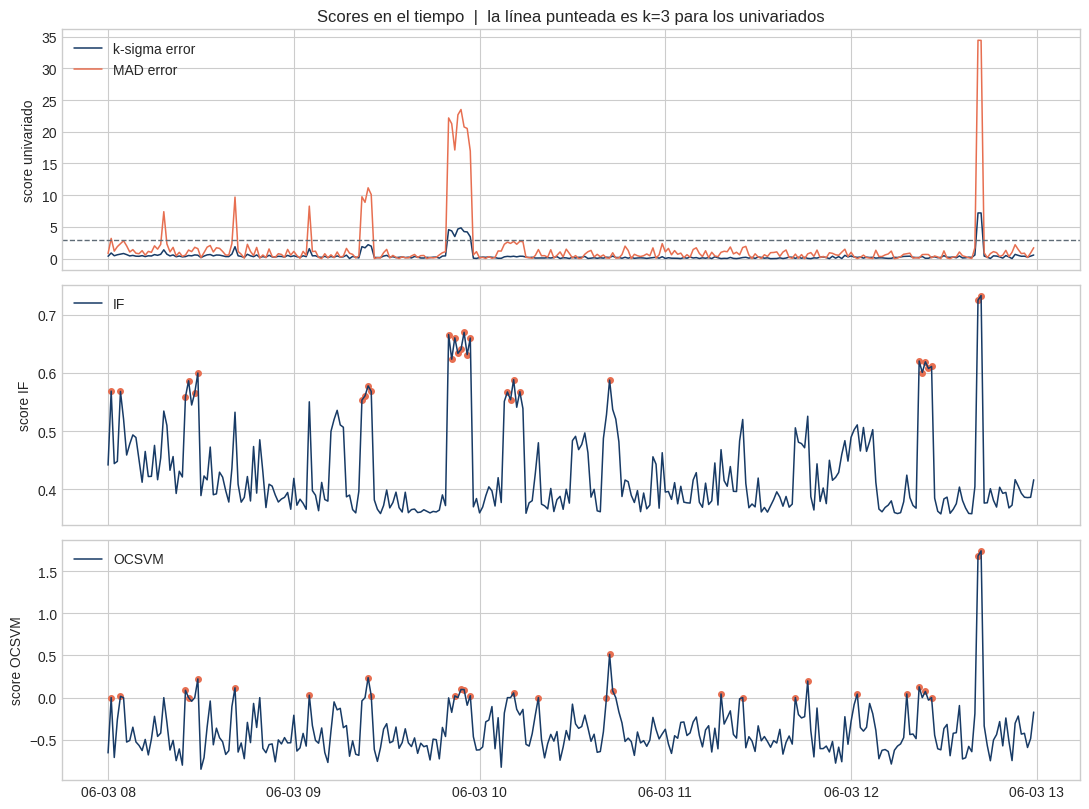

In [49]:
fig, axes = plt.subplots(3, 1, figsize=(11, 8.2), sharex=True)
axes[0].plot(data["timestamp"], data["score_ksigma_error"], color=BLUE, lw=1.1, label="k-sigma error")
axes[0].plot(data["timestamp"], data["score_mad_error"], color=ORANGE, lw=1.1, label="MAD error")
axes[0].axhline(3, color=GRAY, ls="--", lw=1)
axes[0].set_ylabel("score univariado")
axes[0].legend(loc="upper left")

axes[1].plot(data["timestamp"], data["score_if"], color=BLUE, lw=1.1, label="IF")
axes[1].scatter(data.loc[data["flag_if"], "timestamp"], data.loc[data["flag_if"], "score_if"], c=ORANGE, s=16)
axes[1].set_ylabel("score IF")
axes[1].legend(loc="upper left")

axes[2].plot(data["timestamp"], data["score_ocsvm"], color=BLUE, lw=1.1, label="OCSVM")
axes[2].scatter(data.loc[data["flag_ocsvm"], "timestamp"], data.loc[data["flag_ocsvm"], "score_ocsvm"], c=ORANGE, s=16)
axes[2].set_ylabel("score OCSVM")
axes[2].legend(loc="upper left")
axes[0].set_title("Scores en el tiempo  |  la línea punteada es k=3 para los univariados")
plt.tight_layout()
plt.show()


### Por qué los scores se ven diferentes

MAD resalta más los spikes de error porque su escala es menor que el desvío de K-sigma. Los scores IF y OCSVM tienen escalas distintas: no se comparan por su altura absoluta. Cambiar k o `contamination` desplaza el corte; cambiar gamma o nu puede modificar también los scores de OCSVM.


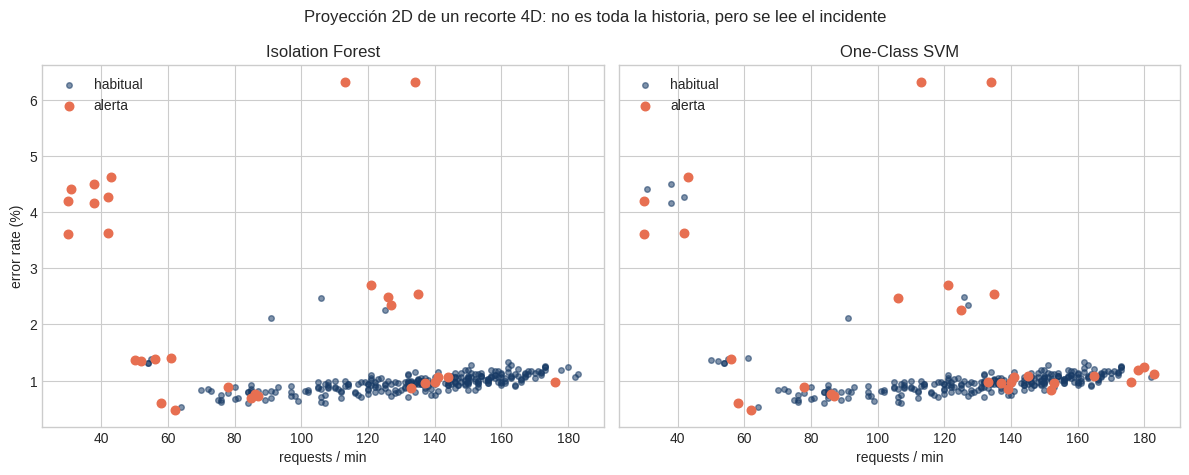

In [50]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), sharex=True, sharey=True)
for ax, flag_col, title in zip(axes, ("flag_if", "flag_ocsvm"), ("Isolation Forest", "One-Class SVM")):
    flags = data[flag_col]
    ax.scatter(data.loc[~flags, "requests"], 100 * data.loc[~flags, "error_rate"], c=BLUE, s=16, alpha=0.55, label="habitual")
    ax.scatter(data.loc[flags, "requests"], 100 * data.loc[flags, "error_rate"], c=ORANGE, s=38, label="alerta")
    ax.set_title(title)
    ax.set_xlabel("requests / min")
    ax.legend(loc="upper left")
axes[0].set_ylabel("error rate (%)")
plt.suptitle("Proyección 2D de un recorte 4D: no es toda la historia, pero se lee el incidente")
plt.tight_layout()
plt.show()


### Lectura de las predicciones 4D proyectadas

El pico de carga sigue la nube habitual y el incidente_5xx se aparta de ella. Una alerta aparentemente normal en este plano puede deberse a CPU o latencia. Aumentar `contamination` o nu suele sumar alertas, pero no permite concluir que una combinación sea un incidente operativo.


## 9. Preguntas (para entregar / discutir)

Respondan con evidencia de las tablas y gráficos, no con la definición del método.

1. Comparen $\sigma$ de k-sigma contra la escala MAD en `error_rate`. ¿Qué le hicieron los `spike_error` y el `micro_burst` a cada una? ¿Se ve el mismo efecto en `latency_ms`?
2. ¿Qué kinds prende k-sigma sobre error rate y **no** prende sobre latencia? ¿Y al revés? ¿Por qué `latencia_silenciosa` es el ejemplo canónico?
3. ¿Algún minuto de `combo_sutil` cruza $k=3$ en un eje solo? Si no, ¿lo ranquean IF u OCSVM cerca de la cima aunque la flag no se encienda?
4. Tomen un minuto de `pico_carga` y uno de `incidente_5xx`. En el plano requests–error rate, ¿quién está al borde de la nube y quién afuera? ¿Coinciden las flags 4D con esa geometría?
5. El `batch` es legítimo. ¿Qué detector lo trata como anomalía y por qué un modo raro (aunque operativo) se parece a un outlier?
6. En `degradacion`, ¿cuál es el primer minuto que cada método enciende? ¿Qué le falta a un detector i.i.d. minuto a minuto?
7. `nu=0.10` y `contamination=0.10` recortan más o menos el mismo presupuesto de alertas. ¿Obtienen el mismo F1? Si no, ¿dónde se pelean?

### Exit ticket

Elijan **un** falso negativo y **un** falso positivo de cualquier método. Para cada uno: el vector $\mathbf x_t$, qué pregunta hacía el detector, y qué cambiarían (feature, umbral o ventana de train) sin romper el resto.


## Resolución de la sección 9 — preguntas, evidencia y respuestas

Cada pregunta se presenta en un bloque, seguida de las tablas o gráficas que permiten verificar sus valores y, finalmente, la respuesta. La evidencia se calcula con las predicciones base de las secciones 4–7; no utiliza los modelos didácticos 2D ni modifica sus flags. Las respuestas redactadas corresponden a la semilla 42 y a los hiperparámetros base.


In [51]:
from sklearn.metrics import confusion_matrix

def evaluar(y, flags):
    p, r, f1, _ = precision_recall_fscore_support(y, flags, average='binary', zero_division=0)
    tn, fp, fn, tp = confusion_matrix(y, flags, labels=[False, True]).ravel()
    return dict(precision=p, recall=r, f1=f1, alertas=int(np.sum(flags)), TP=int(tp), FP=int(fp), FN=int(fn), TN=int(tn))


### Pregunta 1

> Comparen $\sigma$ de k-sigma contra la escala MAD en `error_rate`. ¿Qué le hicieron los `spike_error` y el `micro_burst` a cada una? ¿Se ve el mismo efecto en `latency_ms`?

**Evidencia: tablas y gráficas**


,muestra,feature,n,media,sigma,mediana,escala_MAD
0,todas,error_rate,300,0.011179,0.007221,0.009713,0.001554
1,todas,latency_ms,300,110.465062,38.544746,99.222780,11.620076
2,sin 3 spike_error,error_rate,297,0.011061,0.007159,0.009702,0.001534
3,sin 3 spike_error,latency_ms,297,110.690947,38.669496,99.407106,11.654226
4,sin 2 micro_burst,error_rate,298,0.010830,0.005845,0.009707,0.001540
5,sin 2 micro_burst,latency_ms,298,109.344596,36.148819,99.037745,11.391530
6,sin ambos,error_rate,295,0.010708,0.005745,0.009700,0.001515
7,sin ambos,latency_ms,295,109.560618,36.264477,99.322506,11.506818


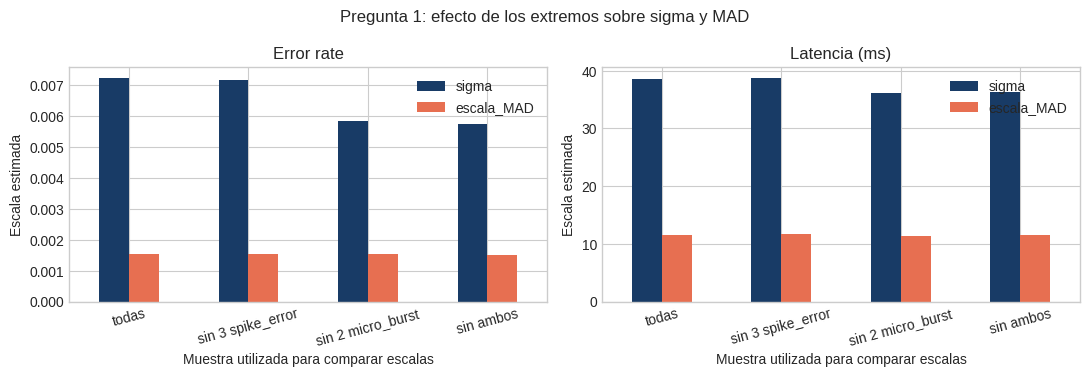

In [52]:
escalas_rows = []
for muestra, mask in {
    'todas': pd.Series(True, index=data.index),
    'sin 3 spike_error': ~data.kind.eq('spike_error'),
    'sin 2 micro_burst': ~data.kind.eq('micro_burst'),
    'sin ambos': ~data.kind.isin(['spike_error', 'micro_burst']),
}.items():
    for feature in ['error_rate', 'latency_ms']:
        s = data.loc[mask, feature]
        mu, sigma = k_sigma_fit(s)
        med, mad, scale = mad_fit(s)
        escalas_rows.append(dict(muestra=muestra, feature=feature, n=len(s), media=mu, sigma=sigma, mediana=med, escala_MAD=scale))
escalas = pd.DataFrame(escalas_rows)
display(escalas.round(6))


fig_escalas9, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, feature, titulo in zip(axes, ['error_rate', 'latency_ms'], ['Error rate', 'Latencia (ms)']):
    muestra = escalas[escalas.feature.eq(feature)].set_index('muestra')
    muestra[['sigma', 'escala_MAD']].plot.bar(ax=ax, color=[BLUE, ORANGE], rot=15)
    ax.set_title(titulo)
    ax.set_xlabel('Muestra utilizada para comparar escalas')
    ax.set_ylabel('Escala estimada')
fig_escalas9.suptitle('Pregunta 1: efecto de los extremos sobre sigma y MAD')
plt.tight_layout()
plt.show()


**Respuesta**

En error, sigma es **0,007221** y la escala MAD **0,001554**: sigma es 4,65 veces mayor. Sin los tres spikes y los dos micro-bursts, pasan a 0,005745 y 0,001515. Los extremos inflan especialmente sigma y ocultan anomalías moderadas. En latencia sucede algo similar: sigma **38,545 ms**, escala MAD **11,620 ms**. Los spikes de error no inyectan latencia; los micro-bursts y otras fallas sí.


### Pregunta 2

> ¿Qué kinds prende k-sigma sobre error rate y **no** prende sobre latencia? ¿Y al revés? ¿Por qué `latencia_silenciosa` es el ejemplo canónico?

**Evidencia: tablas y gráficas**


In [53]:
tabla_ejes9 = counts[['n', 'k-sigma error', 'k-sigma lat', 'MAD error', 'MAD lat']]
print('Minutos alertados por tipo y por KPI (k=3):')
display(tabla_ejes9)
print('Caso latencia_silenciosa:')
display(tabla_ejes9.loc[['latencia_silenciosa']])


Minutos alertados por tipo y por KPI (k=3):


,n,k-sigma error,k-sigma lat,MAD error,MAD lat
kind,,,,,
batch,20,0,0,0,0
combo_sutil,7,0,0,0,0
cpu_latencia,5,0,0,0,5
degradacion,18,0,0,0,11
incidente_5xx,8,8,6,8,8
latencia_silenciosa,6,0,0,0,6
micro_burst,2,2,2,2,2
normal,219,0,0,1,0
pico_carga,8,0,0,0,0


Caso latencia_silenciosa:


,n,k-sigma error,k-sigma lat,MAD error,MAD lat
kind,,,,,
latencia_silenciosa,6,0,0,0,6


**Respuesta**

No hay tipos exclusivos de un eje con k=3: ambos alertan sobre incidente_5xx y micro_burst, aunque detectan distintos minutos. En latencia_silenciosa ambos K-sigma detectan **0/6**. La latencia está elevada, pero el desvío global quedó inflado. **MAD latencia sí detecta 6/6**, mientras MAD error detecta 0/6. Es necesario observar el KPI afectado y usar una escala adecuada.


### Pregunta 3

> ¿Algún minuto de `combo_sutil` cruza $k=3$ en un eje solo? Si no, ¿lo ranquean IF u OCSVM cerca de la cima aunque la flag no se encienda?

**Evidencia: tablas y gráficas**


In [54]:
combo = data.kind.eq('combo_sutil')
combo_ejes_rows = []
for feature in FEATURES:
    mu, sigma = k_sigma_fit(data[feature])
    med, _, scale = mad_fit(data[feature])
    combo_ejes_rows.append(dict(feature=feature, max_k_sigma=k_sigma_score(data.loc[combo, feature], mu, sigma).max(), max_MAD=mad_score(data.loc[combo, feature], med, scale).max(), n_k_sigma_sobre3=int((k_sigma_score(data.loc[combo, feature], mu, sigma)>3).sum()), n_MAD_sobre3=int((mad_score(data.loc[combo, feature], med, scale)>3).sum())))
combo_ejes = pd.DataFrame(combo_ejes_rows).set_index('feature')
display(combo_ejes.round(4))

data['rank_if'] = data.score_if.rank(ascending=False, method='min').astype(int)
data['rank_ocsvm'] = data.score_ocsvm.rank(ascending=False, method='min').astype(int)
combo_ranking = data.loc[combo, ['timestamp', 'score_if', 'rank_if', 'flag_if', 'score_ocsvm', 'rank_ocsvm', 'flag_ocsvm']]
display(combo_ranking.round(5))


,max_k_sigma,max_MAD,n_k_sigma_sobre3,n_MAD_sobre3
feature,,,,
requests,2.4123,3.0352,0,1
error_rate,0.3836,2.7267,0,0
latency_ms,0.4331,2.4040,0,0
cpu_pct,1.7718,2.9813,0,0


,timestamp,score_if,rank_if,flag_if,score_ocsvm,rank_ocsvm,flag_ocsvm
128,2026-06-03 10:08:00,0.55109,31,False,-0.18251,64,False
129,2026-06-03 10:09:00,0.56713,25,True,-0.00009,32,False
130,2026-06-03 10:10:00,0.55375,29,True,-0.00015,33,False
131,2026-06-03 10:11:00,0.58830,17,True,0.05631,14,True
132,2026-06-03 10:12:00,0.54089,34,False,-0.13832,57,False
133,2026-06-03 10:13:00,0.56771,24,True,-0.20595,68,False
134,2026-06-03 10:14:00,0.53874,35,False,-0.13930,58,False


**Respuesta**

En error y latencia no supera 3 con ninguno de los dos métodos. Hay una excepción al comentario del generador: a las **10:09**, requests=50 produce **3,035208 MAD** sobre requests. IF coloca estos minutos en posiciones **17–35** del ranking y detecta **4/7**; OCSVM los coloca en **14–68** y detecta **1/7**. La posición 1 es la más anómala. Un score relativamente alto puede quedar fuera del corte de alertas.


### Pregunta 4

> Tomen un minuto de `pico_carga` y uno de `incidente_5xx`. En el plano requests–error rate, ¿quién está al borde de la nube y quién afuera? ¿Coinciden las flags 4D con esa geometría?

**Evidencia: tablas y gráficas**


Un minuto real de cada tipo, con su vector y sus flags 4D:


,timestamp,kind,requests,error_rate,latency_ms,cpu_pct,flag_if,flag_ocsvm
110,2026-06-03 09:50:00,incidente_5xx,31.0,0.044165,249.332486,33.959086,True,False
198,2026-06-03 11:18:00,pico_carga,183.0,0.011262,104.457456,46.676667,False,True


Total de minutos alertados en cada evento:


,n,Isolation Forest,One-Class SVM
kind,,,
pico_carga,8,0,2
incidente_5xx,8,8,4


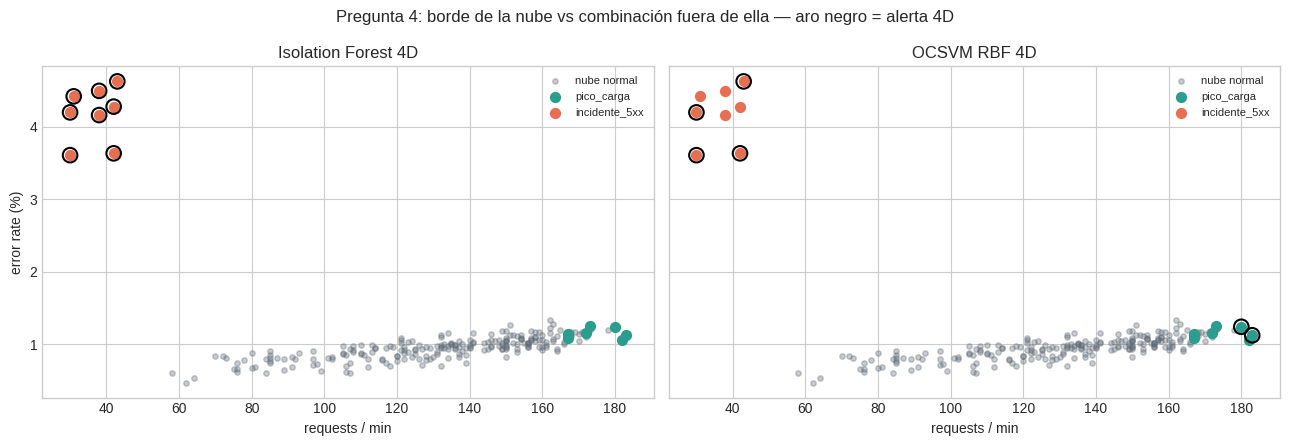

In [55]:
tipos_geometria9 = ['pico_carga', 'incidente_5xx']
ejemplos_geometria9 = data[data.kind.isin(tipos_geometria9)].groupby('kind', sort=False).head(1)
print('Un minuto real de cada tipo, con su vector y sus flags 4D:')
display(ejemplos_geometria9[['timestamp', 'kind', *FEATURES, 'flag_if', 'flag_ocsvm']].round(6))
print('Total de minutos alertados en cada evento:')
display(counts.loc[tipos_geometria9, ['n', 'Isolation Forest', 'One-Class SVM']])
fig_geometria9, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharex=True, sharey=True)
for ax, flag_col, titulo in zip(axes, ['flag_if', 'flag_ocsvm'], ['Isolation Forest 4D', 'OCSVM RBF 4D']):
    normales = data.kind.eq('normal')
    ax.scatter(data.loc[normales, 'requests'], 100*data.loc[normales, 'error_rate'], c=GRAY, s=15, alpha=.35, label='nube normal')
    for tipo, color in [('pico_carga', GREEN), ('incidente_5xx', ORANGE)]:
        mask = data.kind.eq(tipo)
        ax.scatter(data.loc[mask, 'requests'], 100*data.loc[mask, 'error_rate'], c=color, s=50, label=tipo)
        alertas = mask & data[flag_col]
        ax.scatter(data.loc[alertas, 'requests'], 100*data.loc[alertas, 'error_rate'], facecolors='none', edgecolors='black', s=110, linewidths=1.5)
    ax.set(xlabel='requests / min', title=titulo)
    ax.legend(fontsize=8)
axes[0].set_ylabel('error rate (%)')
fig_geometria9.suptitle('Pregunta 4: borde de la nube vs combinación fuera de ella — aro negro = alerta 4D')
plt.tight_layout()
plt.show()


**Respuesta**

El pico de carga continúa la relación normal entre requests y error. El incidente combina pocas requests, mucho error y alta latencia: se sale de esa relación. IF alerta **0/8** minutos del pico y **8/8** del incidente; OCSVM alerta **2/8** y **4/8**. La gráfica es una proyección: ambos modelos usan las cuatro métricas.


### Pregunta 5

> El `batch` es legítimo. ¿Qué detector lo trata como anomalía y por qué un modo raro (aunque operativo) se parece a un outlier?

**Evidencia: tablas y gráficas**


Batch legítimo: minutos alertados por cada detector:


,n,k-sigma error,k-sigma lat,MAD error,MAD lat,Isolation Forest,One-Class SVM
kind,,,,,,,
batch,20,0,0,0,0,4,5


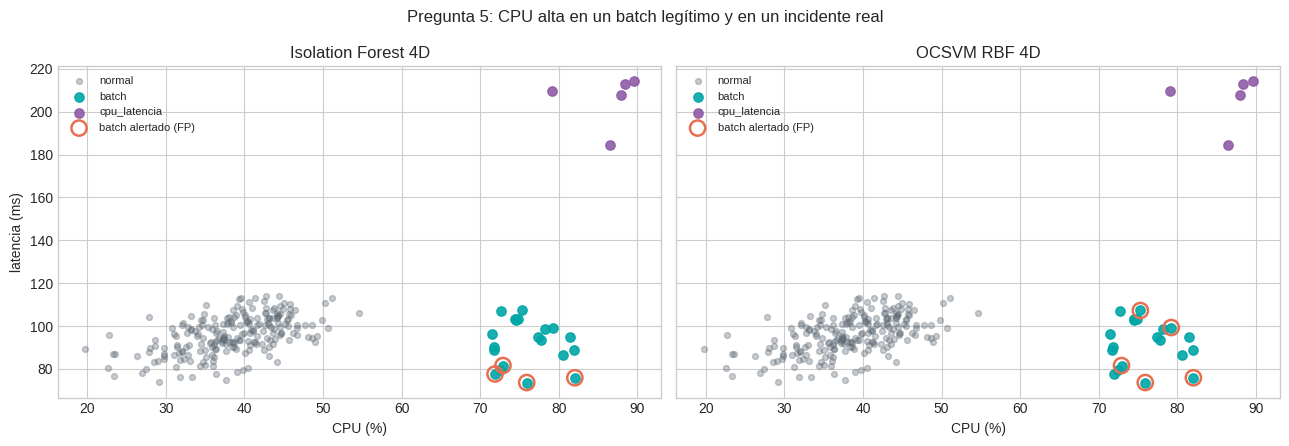

In [56]:
print('Batch legítimo: minutos alertados por cada detector:')
display(counts.loc[['batch'], ['n', *FLAG_COLS]])
fig_batch9, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharex=True, sharey=True)
for ax, flag_col, titulo in zip(axes, ['flag_if', 'flag_ocsvm'], ['Isolation Forest 4D', 'OCSVM RBF 4D']):
    for tipo, color in [('normal', GRAY), ('batch', TEAL), ('cpu_latencia', PURPLE)]:
        mask = data.kind.eq(tipo)
        ax.scatter(data.loc[mask, 'cpu_pct'], data.loc[mask, 'latency_ms'], c=color, s=18 if tipo=='normal' else 45, alpha=.35 if tipo=='normal' else .9, label=tipo)
    fp_batch = data.kind.eq('batch') & data[flag_col]
    ax.scatter(data.loc[fp_batch, 'cpu_pct'], data.loc[fp_batch, 'latency_ms'], facecolors='none', edgecolors=ORANGE, s=120, linewidths=1.8, label='batch alertado (FP)')
    ax.set(xlabel='CPU (%)', title=titulo)
    ax.legend(fontsize=8)
axes[0].set_ylabel('latencia (ms)')
fig_batch9.suptitle('Pregunta 5: CPU alta en un batch legítimo y en un incidente real')
plt.tight_layout()
plt.show()


**Respuesta**

IF alerta **4/20** y OCSVM **5/20**; los univariados no alertan. El batch tiene CPU alta con el resto de los indicadores habituales. Es poco frecuente, pero está autorizado: **rareza estadística no equivale a incidente**. Incluir contexto del job o ejemplos representativos de batch puede reducir estos falsos positivos; habría que verificar que las fallas reales de CPU sigan detectándose.


### Pregunta 6

> En `degradacion`, ¿cuál es el primer minuto que cada método enciende? ¿Qué le falta a un detector i.i.d. minuto a minuto?

**Evidencia: tablas y gráficas**


,detector,primera_alerta,demora_min,alertas
0,k-sigma error,NaT,NaN,0
1,k-sigma lat,NaT,NaN,0
2,MAD error,NaT,NaN,0
3,MAD lat,2026-06-03 11:57:00,7.0,11
4,Isolation Forest,NaT,NaN,0
5,One-Class SVM,2026-06-03 12:02:00,12.0,1


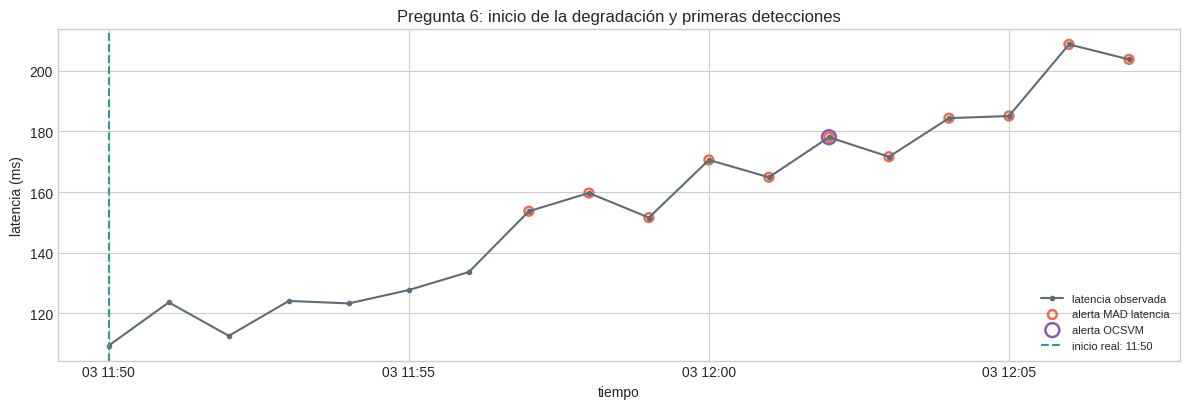

In [57]:
degradacion = data.kind.eq('degradacion')
inicio_deg = data.loc[degradacion, 'timestamp'].min()
primeras_rows = []
for nombre, col in FLAG_COLS.items():
    ts = data.loc[degradacion & data[col], 'timestamp']
    primera = ts.min() if len(ts) else pd.NaT
    primeras_rows.append(dict(detector=nombre, primera_alerta=primera, demora_min=(primera-inicio_deg).total_seconds()/60 if len(ts) else np.nan, alertas=int(len(ts))))
primeras = pd.DataFrame(primeras_rows)
display(primeras)


fig_degradacion9, ax = plt.subplots(figsize=(12, 4.2))
tramo = data.loc[degradacion]
ax.plot(tramo.timestamp, tramo.latency_ms, color=GRAY, marker='.', label='latencia observada')
for flag_col, color, label in [('flag_mad_lat', ORANGE, 'MAD latencia'), ('flag_ocsvm', PURPLE, 'OCSVM')]:
    mask = degradacion & data[flag_col]
    ax.scatter(data.loc[mask, 'timestamp'], data.loc[mask, 'latency_ms'], facecolors='none', edgecolors=color, s=100 if flag_col=='flag_ocsvm' else 40, linewidths=1.8, label='alerta '+label)
ax.axvline(inicio_deg, color=GREEN, ls='--', label='inicio real: 11:50')
ax.set(xlabel='tiempo', ylabel='latencia (ms)', title='Pregunta 6: inicio de la degradación y primeras detecciones')
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()


**Respuesta**

Comienza a las **11:50**. MAD latencia alerta por primera vez a las **11:57** y detecta **11/18** minutos. OCSVM comienza a las **12:02** y detecta **1/18**. Los demás no alertan. Estos modelos miran cada minuto por separado: no conocen la tendencia acumulada. Agregaría pendiente o persistencia calculadas con ventanas pasadas, sin usar información futura.


### Pregunta 7

> `nu=0.10` y `contamination=0.10` recortan más o menos el mismo presupuesto de alertas. ¿Obtienen el mismo F1? Si no, ¿dónde se pelean?

**Evidencia: tablas y gráficas**


Evaluación de IF y OCSVM sobre las 300 ventanas:


,precision,recall,f1,alertas,TP,FP,FN,TN
Isolation Forest,0.8000,0.4528,0.5783,30.0,24.0,6.0,29.0,241.0
One-Class SVM,0.6207,0.3396,0.4390,29.0,18.0,11.0,35.0,236.0


Comparación por tipo:


,n,anómalo?,Isolation Forest,One-Class SVM
kind,,,,
batch,20,False,4,5
combo_sutil,7,True,4,1
cpu_latencia,5,True,5,3
degradacion,18,True,0,1
incidente_5xx,8,True,8,4
latencia_silenciosa,6,True,1,3
micro_burst,2,True,2,2
normal,219,False,2,4
pico_carga,8,False,0,2


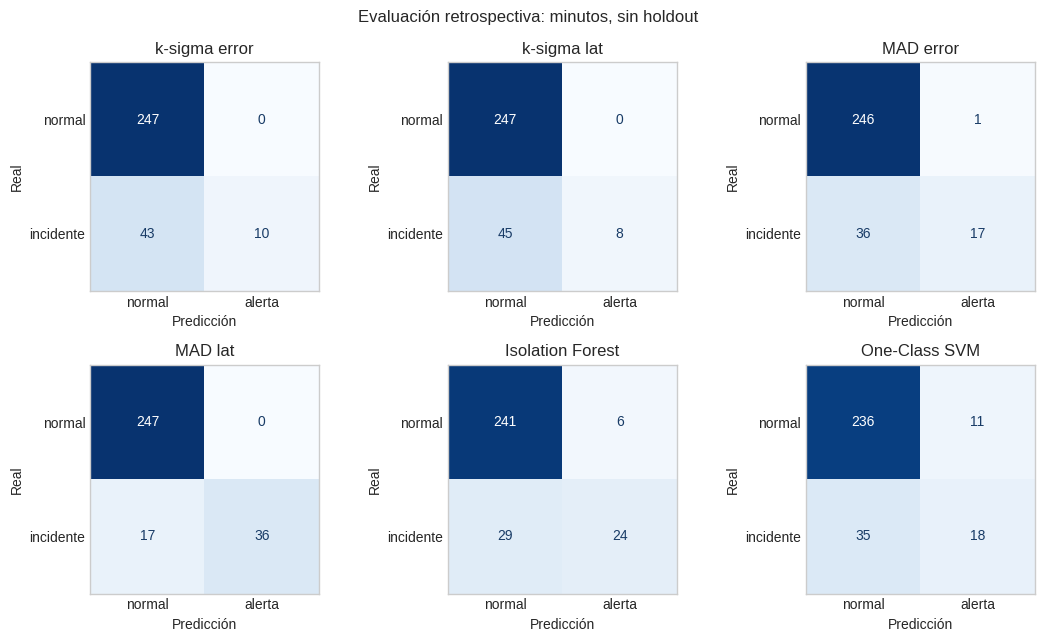

In [58]:
metricas_detalle = pd.DataFrame({nombre: evaluar(data.is_anomaly, data[col]) for nombre, col in FLAG_COLS.items()}).T
print('Evaluación de IF y OCSVM sobre las 300 ventanas:')
display(metricas_detalle.loc[['Isolation Forest', 'One-Class SVM']].round(4))
print('Comparación por tipo:')
display(counts[['n', 'anómalo?', 'Isolation Forest', 'One-Class SVM']])
fig_confusiones, axes = plt.subplots(2, 3, figsize=(11, 6.5))
for ax, (nombre, col) in zip(axes.ravel(), FLAG_COLS.items()):
    cm = confusion_matrix(data.is_anomaly, data[col], labels=[False, True])
    ax.imshow(cm, cmap='Blues', vmin=0, vmax=250)
    ax.grid(False)
    for (i, j), val in np.ndenumerate(cm):
        ax.text(j, i, str(val), ha='center', va='center', color='white' if val > 130 else BLUE)
    ax.set(xticks=[0, 1], yticks=[0, 1], xticklabels=['normal', 'alerta'], yticklabels=['normal', 'incidente'], title=nombre, xlabel='Predicción', ylabel='Real')
fig_confusiones.suptitle('Evaluación retrospectiva: minutos, sin holdout')
fig_confusiones.tight_layout()
plt.show()


**Respuesta**

No. IF genera **30 alertas**, con **24 aciertos y 6 falsos positivos**, F1 **0,578**. OCSVM genera **29**, con **18 aciertos y 11 falsos positivos**, F1 **0,439**. IF detecta mejor incidente_5xx y combo_sutil; OCSVM detecta más latencia_silenciosa y spikes, pero también más casos legítimos. contamination fija un corte en IF; nu participa en el ajuste de OCSVM y no garantiza exactamente 10% de alertas.


### Exit ticket

> Elijan **un** falso negativo y **un** falso positivo de cualquier método. Para cada uno: el vector $\mathbf x_t$, qué pregunta hacía el detector, y qué cambiarían (feature, umbral o ventana de train) sin romper el resto.


In [59]:
fn_elegido9 = data[data.is_anomaly & ~data.flag_if & data.kind.eq('combo_sutil')].head(1).copy()
fp_elegido9 = data[~data.is_anomaly & data.flag_ocsvm & data.kind.eq('batch')].head(1).copy()
fn_elegido9['caso'] = 'Falso negativo de IF'
fp_elegido9['caso'] = 'Falso positivo de OCSVM'
casos_exit9 = pd.concat([fn_elegido9, fp_elegido9])
display(casos_exit9[['caso', 'timestamp', 'kind', *FEATURES, 'is_anomaly', 'flag_if', 'score_if', 'rank_if', 'flag_ocsvm', 'score_ocsvm', 'rank_ocsvm']].round(6))
display(pd.Series({'corte_score_IF': -forest.offset_, 'corte_score_OCSVM': 0.0}, name='Umbral de alerta (score > corte)').to_frame())


,caso,timestamp,kind,requests,error_rate,latency_ms,cpu_pct,is_anomaly,flag_if,score_if,rank_if,flag_ocsvm,score_ocsvm,rank_ocsvm
128,Falso negativo de IF,2026-06-03 10:08:00,combo_sutil,54.0,0.013232,119.175044,24.291131,True,False,0.551088,31,False,-0.182509,64
25,Falso positivo de OCSVM,2026-06-03 08:25:00,batch,78.0,0.008835,81.592230,72.897792,False,True,0.558806,28,True,0.086654,11


,Umbral de alerta (score > corte)
corte_score_IF,0.551295
corte_score_OCSVM,0.000000


**Respuesta**

**Falso negativo de IF — 10:08, combo_sutil.** Vector: `(requests=54, error_rate=0.013232, latency_ms=119.175, cpu_pct=24.291)`. Score **0,551088**, por debajo del corte **0,551295**; puesto 31 con presupuesto de 30 alertas. IF pregunta si el punto se aísla rápidamente. Probaría residuales de error/latencia respecto de la carga. Subir contamination podría detectarlo, a costa de más falsos positivos.

**Falso positivo de OCSVM — 08:25, batch.** Vector: `(requests=78, error_rate=0.008835, latency_ms=81.592, cpu_pct=72.898)`. Score **0,086654 > 0**: queda fuera de la frontera, aunque es legítimo. Probaría una referencia que incluya jobs autorizados o contexto del job, conservando CPU para detectar incidentes reales. Estos cambios requieren validación; no garantizan conservar todos los aciertos.


### 10. Experimentos de hiperparámetros

Las tablas cambian **un parámetro por vez**: así podemos atribuir la diferencia a ese cambio. K y `contamination` mueven cortes; árboles, muestra, nu y gamma pueden cambiar los scores. Las métricas se calculan sobre las mismas 300 ventanas de ajuste: una mejora aquí todavía no demuestra generalización.


,detector,k,precision,recall,f1,alertas,TP,FP,FN,TN
0,k-sigma error,2.0,1.0000,0.2075,0.3438,11,11,0,42,247
1,k-sigma error,2.5,1.0000,0.1887,0.3175,10,10,0,43,247
2,k-sigma error,3.0,1.0000,0.1887,0.3175,10,10,0,43,247
3,k-sigma error,3.5,1.0000,0.1509,0.2623,8,8,0,45,247
4,k-sigma error,4.0,1.0000,0.1509,0.2623,8,8,0,45,247
5,k-sigma error,5.0,1.0000,0.0377,0.0727,2,2,0,51,247
6,k-sigma lat,2.0,1.0000,0.4717,0.6410,25,25,0,28,247
7,k-sigma lat,2.5,1.0000,0.3774,0.5479,20,20,0,33,247
8,k-sigma lat,3.0,1.0000,0.1509,0.2623,8,8,0,45,247
9,k-sigma lat,3.5,1.0000,0.0943,0.1724,5,5,0,48,247


,parametro,valor,umbral,ranking_igual_base,precision,recall,f1,alertas,TP,FP,FN,TN
0,contamination,0.03,0.6237,True,1.0000,0.1698,0.2903,9,9,0,44,247
1,contamination,0.05,0.5996,True,1.0000,0.2830,0.4412,15,15,0,38,247
2,contamination,0.10,0.5513,True,0.8000,0.4528,0.5783,30,24,6,29,241
3,contamination,0.15,0.5120,True,0.7333,0.6226,0.6735,45,33,12,20,235
4,contamination,0.20,0.4855,True,0.6500,0.7358,0.6903,60,39,21,14,226
5,contamination,0.25,0.4689,True,0.5600,0.7925,0.6562,75,42,33,11,214
6,n_estimators,50.00,0.5478,False,0.8667,0.4906,0.6265,30,26,4,27,243
7,n_estimators,100.00,0.5478,False,0.8000,0.4528,0.5783,30,24,6,29,241
8,n_estimators,300.00,0.5513,True,0.8000,0.4528,0.5783,30,24,6,29,241
9,n_estimators,600.00,0.5468,False,0.8000,0.4528,0.5783,30,24,6,29,241


,parametro,valor,gamma_efectivo,fraccion_SV,precision,recall,f1,alertas,TP,FP,FN,TN
0,nu,0.03,0.25,0.0800,0.5455,0.1132,0.1875,11,6,5,47,242
1,nu,0.05,0.25,0.0900,0.6875,0.2075,0.3188,16,11,5,42,242
2,nu,0.10,0.25,0.1300,0.6207,0.3396,0.4390,29,18,11,35,236
3,nu,0.15,0.25,0.1667,0.6444,0.5472,0.5918,45,29,16,24,231
4,nu,0.20,0.25,0.2133,0.6000,0.6792,0.6372,60,36,24,17,223
5,gamma,0.01,0.01,0.1067,0.4839,0.2830,0.3571,31,15,16,38,231
6,gamma,0.08,0.08,0.1200,0.6452,0.3774,0.4762,31,20,11,33,236
7,gamma,0.25,0.25,0.1300,0.6207,0.3396,0.4390,29,18,11,35,236
8,gamma,0.50,0.50,0.1367,0.7143,0.3774,0.4938,28,20,8,33,239
9,gamma,2.00,2.00,0.2600,0.3421,0.2453,0.2857,38,13,25,40,222


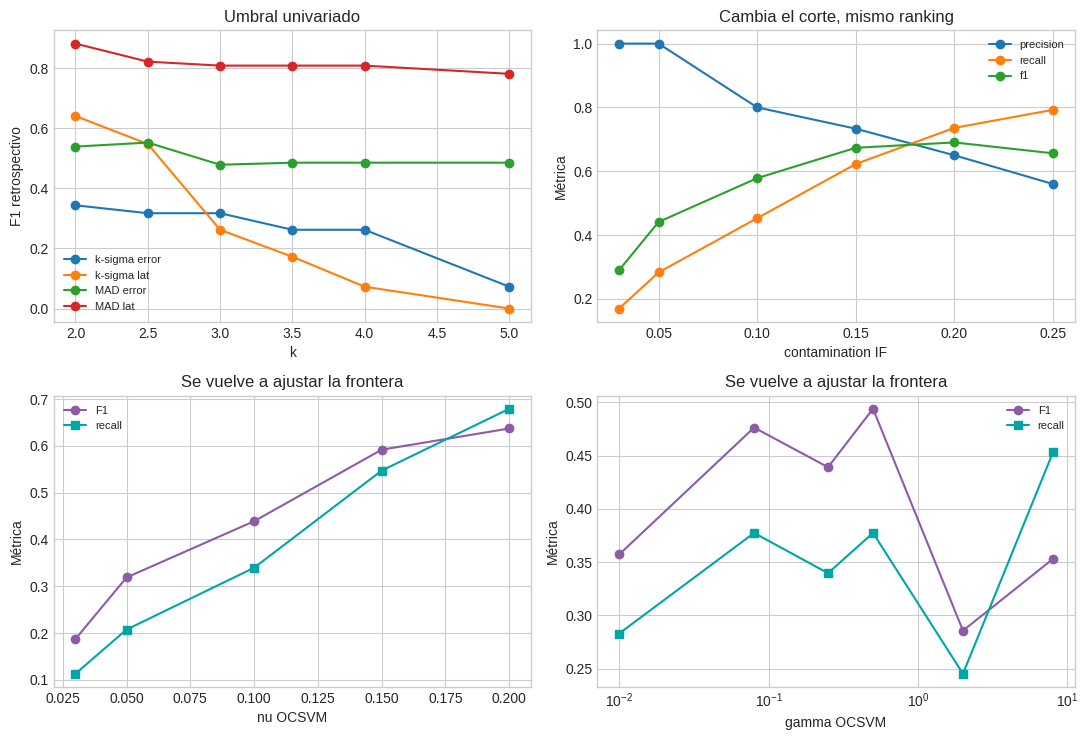

In [60]:
filas_k = []
for nombre, col in {
    'k-sigma error': 'score_ksigma_error', 'k-sigma lat': 'score_ksigma_lat',
    'MAD error': 'score_mad_error', 'MAD lat': 'score_mad_lat',
}.items():
    for k in [2.0, 2.5, 3.0, 3.5, 4.0, 5.0]:
        filas_k.append(dict(detector=nombre, k=k, **evaluar(data.is_anomaly, data[col] > k)))
sens_k = pd.DataFrame(filas_k)
display(sens_k.round(4))

filas_if = []
for parametro, valores in {
    'contamination': [0.03, 0.05, 0.10, 0.15, 0.20, 0.25],
    'n_estimators': [50, 100, 300, 600],
    'max_samples': [64, 128, 256],
}.items():
    for valor in valores:
        params = dict(n_estimators=300, max_samples=min(256, len(data)), contamination=0.10, random_state=SEED)
        params[parametro] = valor
        model = IsolationForest(**params).fit(X_all)
        flags = model.predict(X_all) == -1
        scores = -model.score_samples(X_all)
        filas_if.append(dict(parametro=parametro, valor=valor, umbral=-model.offset_, ranking_igual_base=bool(np.allclose(scores, data.score_if)), **evaluar(data.is_anomaly, flags)))
sens_if = pd.DataFrame(filas_if)
display(sens_if.round(4))

filas_oc = []
for parametro, valores in {'nu': [0.03, 0.05, 0.10, 0.15, 0.20], 'gamma': [0.01, 0.08, 0.25, 0.50, 2.0, 8.0]}.items():
    for valor in valores:
        params = dict(kernel='rbf', nu=0.10, gamma='scale')
        params[parametro] = valor
        model = OneClassSVM(**params).fit(X_all)
        flags = model.predict(X_all) == -1
        filas_oc.append(dict(parametro=parametro, valor=valor, gamma_efectivo=model._gamma, fraccion_SV=len(model.support_)/len(data), **evaluar(data.is_anomaly, flags)))
sens_oc = pd.DataFrame(filas_oc)
display(sens_oc.round(4))

fig_sensibilidad, axes = plt.subplots(2, 2, figsize=(11, 7.5))
for nombre, grupo in sens_k.groupby('detector', sort=False):
    axes[0, 0].plot(grupo.k, grupo.f1, marker='o', label=nombre)
axes[0, 0].set(xlabel='k', ylabel='F1 retrospectivo', title='Umbral univariado')
axes[0, 0].legend(fontsize=8)
g = sens_if[sens_if.parametro.eq('contamination')]
for col in ['precision', 'recall', 'f1']:
    axes[0, 1].plot(g.valor, g[col], marker='o', label=col)
axes[0, 1].set(xlabel='contamination IF', ylabel='Métrica', title='Cambia el corte, mismo ranking')
axes[0, 1].legend(fontsize=8)
for ax, param in zip(axes[1], ['nu', 'gamma']):
    g = sens_oc[sens_oc.parametro.eq(param)]
    ax.plot(g.valor, g.f1, marker='o', color=PURPLE, label='F1')
    ax.plot(g.valor, g.recall, marker='s', color=TEAL, label='recall')
    if param == 'gamma':
        ax.set_xscale('log')
    ax.set(xlabel=param+' OCSVM', ylabel='Métrica', title='Se vuelve a ajustar la frontera')
    ax.legend(fontsize=8)
fig_sensibilidad.tight_layout()
plt.show()


### Lectura de las tablas y curvas

- **k:** al bajar de 3 a 2, MAD latencia sube de 36 a 45 aciertos, pero agrega 4 falsos positivos; al subir a 5 baja a 34 aciertos.
- **contamination:** subir de 0,10 a 0,20 aumenta el recall de IF, pero las falsas alertas pasan de 6 a 21; bajarlo a 0,05 deja 0 falsas y solo 15 aciertos.
- **Árboles y muestra:** 50 árboles o muestra=64 dan F1=0,627, frente a 0,578 en la base; aumentar estos valores no mejora necesariamente el resultado.
- **nu y gamma:** nu mayor suele generar más alertas; gamma alto puede fragmentar la frontera. Gamma demasiado bajo puede ocultar combinaciones raras.

Cambiar un corte no prueba sobreajuste. Para distinguirlo de una mala calibración hay que evaluar datos separados.


## Referencias del curso y uso de IA

Se utilizó OpenAI Codex como apoyo para implementar, ejecutar, comprobar resultados.

### 11. Exploración interactiva

Las barras permiten comprobar el compromiso entre anomalías detectadas y falsas alertas. **Ejecutar las celdas y soltar cada barra** para actualizar; requieren `ipywidgets` (`%pip install ipywidgets` si falta). Los paneles 11.1–11.3 usan el protocolo principal; 11.4–11.5 son demostraciones 2D. Estos experimentos no modifican las flags base.


In [61]:
try:
    import ipywidgets as widgets
    WIDGETS_AVAILABLE = True
except ImportError:
    WIDGETS_AVAILABLE = False
    print('Para usar las barras: ejecutar %pip install ipywidgets y reiniciar el kernel.')

def resumen_panel(flags):
    m = evaluar(data['is_anomaly'], flags)
    return (f"Alertas={m['alertas']} | TP={m['TP']} | FP={m['FP']} | "
            f"FN={m['FN']} | precisión={m['precision']:.3f} | "
            f"recall={m['recall']:.3f} | F1={m['f1']:.3f}")

def slider_real(valor, minimo, maximo, paso, nombre):
    return widgets.FloatSlider(value=valor, min=minimo, max=maximo, step=paso,
                               description=nombre, continuous_update=False,
                               readout_format='.2f', style={'description_width': 'initial'})


### 11.1 Umbral univariado

La vista inicial usa MAD latencia con k=3: **36 aciertos y 0 falsas alertas**. Al bajar k la banda se estrecha y aparecen más alertas; al subirlo se ensancha y se pierden anomalías moderadas. Cambiar a K-sigma muestra cómo el desvío inflado reduce la sensibilidad incluso con el mismo k.


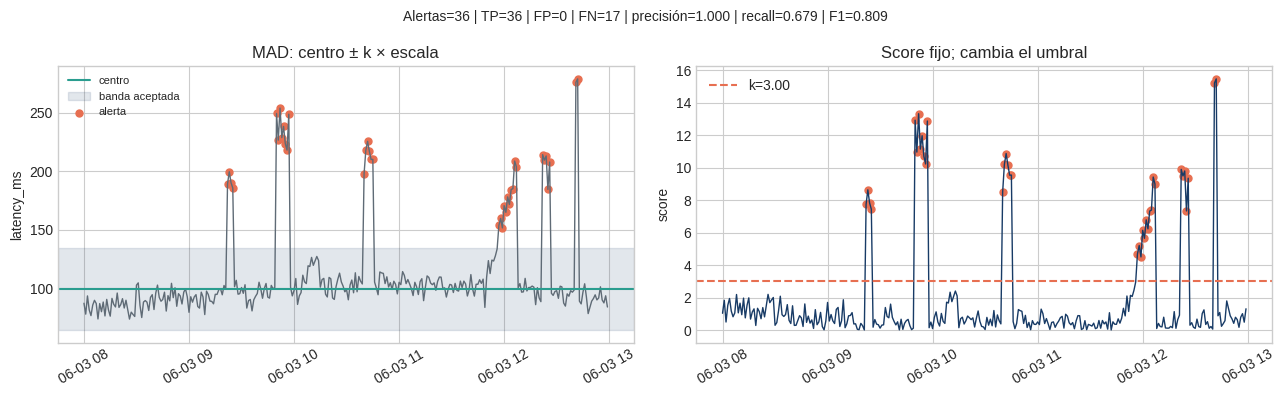

interactive(children=(Dropdown(description='Método', index=1, options=('K-sigma', 'MAD'), value='MAD'), Dropdo…

In [62]:
def explorar_umbral(metodo='MAD', feature='latency_ms', k=3.0):
    serie = data[feature]
    if metodo == 'K-sigma':
        centro, escala = k_sigma_fit(serie)
        score = k_sigma_score(serie, centro, escala)
    else:
        centro, _, escala = mad_fit(serie)
        score = mad_score(serie, centro, escala)
    flags = score > k
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    axes[0].plot(data.timestamp, serie, color=GRAY, lw=1)
    axes[0].axhline(centro, color=GREEN, label='centro')
    axes[0].axhspan(centro-k*escala, centro+k*escala, color=BLUE, alpha=.12, label='banda aceptada')
    axes[0].scatter(data.loc[flags, 'timestamp'], serie[flags], c=ORANGE, s=25, label='alerta')
    axes[0].set(ylabel=feature, title=f'{metodo}: centro ± k × escala')
    axes[0].legend(fontsize=8)
    axes[1].plot(data.timestamp, score, color=BLUE, lw=1)
    axes[1].axhline(k, color=ORANGE, ls='--', label=f'k={k:.2f}')
    axes[1].scatter(data.loc[flags, 'timestamp'], score[flags], c=ORANGE, s=25)
    axes[1].set(ylabel='score', title='Score fijo; cambia el umbral')
    axes[1].legend()
    for ax in axes:
        ax.tick_params(axis='x', rotation=30)
    fig.suptitle(resumen_panel(flags), fontsize=10)
    fig.tight_layout()
    plt.show()

# Vista inicial guardada en el archivo para poder verla antes de ejecutar.
explorar_umbral()
if WIDGETS_AVAILABLE:
    widgets.interact(explorar_umbral,
        metodo=widgets.Dropdown(options=['K-sigma', 'MAD'], value='MAD', description='Método'),
        feature=widgets.Dropdown(options=['error_rate', 'latency_ms'], value='latency_ms', description='Métrica'),
        k=slider_real(3, .5, 6, .25, 'k'))

### 11.2 Presupuesto de alertas de IF

Con los valores iniciales se activan **30 minutos: 24 aciertos y 6 falsas alertas**. Subir `contamination` baja el corte del score e incorpora más puntos; bajarlo conserva los más raros. Árboles y muestra sí pueden cambiar el ranking: más árboles tienden a estabilizarlo y una muestra diferente puede representar otros patrones.


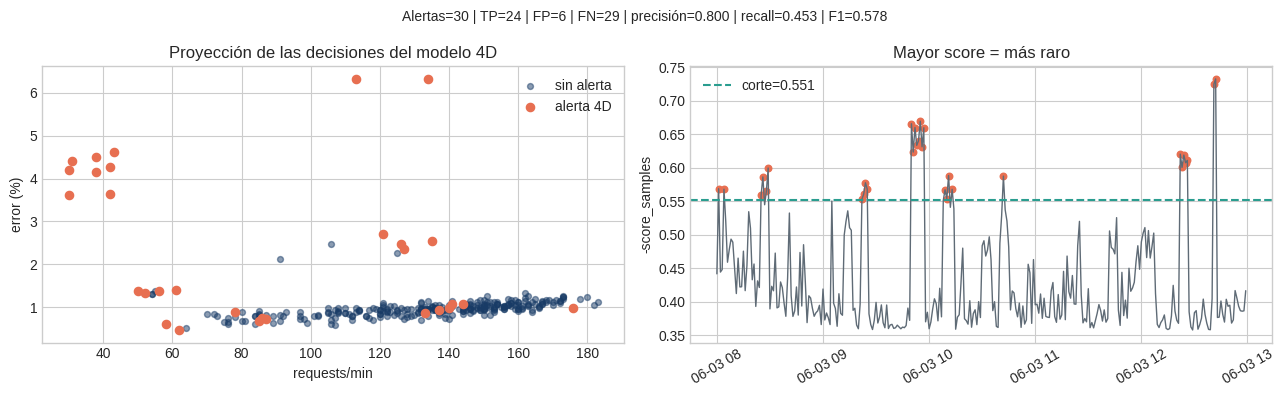

interactive(children=(FloatSlider(value=0.1, continuous_update=False, description='contamination', max=0.3, mi…

In [63]:
def explorar_if(contamination=.10, arboles=300, muestra=256):
    modelo = IsolationForest(n_estimators=arboles, max_samples=muestra,
                             contamination=contamination, random_state=SEED).fit(X_all)
    score = -modelo.score_samples(X_all)
    flags = modelo.predict(X_all) == -1
    corte = -modelo.offset_
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    axes[0].scatter(data.requests[~flags], 100*data.error_rate[~flags], c=BLUE, s=18, alpha=.5, label='sin alerta')
    axes[0].scatter(data.requests[flags], 100*data.error_rate[flags], c=ORANGE, s=35, label='alerta 4D')
    axes[0].set(xlabel='requests/min', ylabel='error (%)', title='Proyección de las decisiones del modelo 4D')
    axes[0].legend()
    axes[1].plot(data.timestamp, score, color=GRAY, lw=1)
    axes[1].axhline(corte, color=GREEN, ls='--', label=f'corte={corte:.3f}')
    axes[1].scatter(data.timestamp[flags], score[flags], c=ORANGE, s=22)
    axes[1].set(ylabel='-score_samples', title='Mayor score = más raro')
    axes[1].tick_params(axis='x', rotation=30)
    axes[1].legend()
    fig.suptitle(resumen_panel(flags), fontsize=10)
    fig.tight_layout()
    plt.show()

explorar_if()
if WIDGETS_AVAILABLE:
    widgets.interact(explorar_if,
        contamination=slider_real(.10, .01, .30, .01, 'contamination'),
        arboles=widgets.IntSlider(value=300, min=50, max=600, step=50, description='Árboles', continuous_update=False),
        muestra=widgets.IntSlider(value=256, min=32, max=300, step=1, description='Muestra', continuous_update=False))

### 11.3 Frontera de OCSVM

La vista inicial 4D usa nu=0,10 y gamma=0,25: **29 alertas, 11 falsas**. Subir nu suele dejar menos puntos aceptados; bajarlo suele aceptar más. Subir gamma vuelve la frontera más local; bajarlo la suaviza y puede aceptar incidentes. Conviene mirar FP y FN juntos, porque la cantidad de alertas no determina su utilidad.


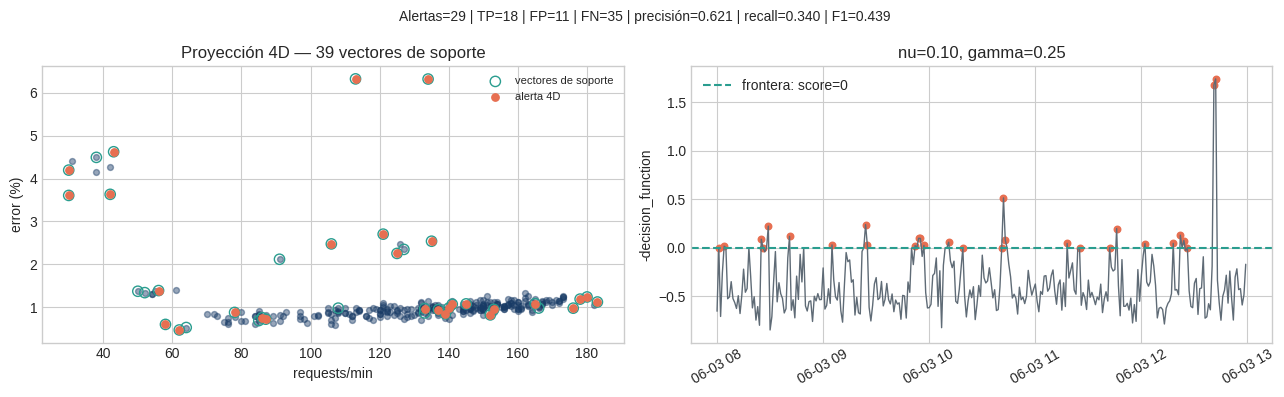

interactive(children=(FloatSlider(value=0.1, continuous_update=False, description='nu', max=0.3, min=0.02, ste…

In [64]:
def explorar_ocsvm(nu=.10, gamma=.25):
    modelo = OneClassSVM(kernel='rbf', nu=nu, gamma=gamma).fit(X_all)
    score = -modelo.decision_function(X_all)
    flags = modelo.predict(X_all) == -1
    sv = modelo.support_
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    axes[0].scatter(data.requests, 100*data.error_rate, c=BLUE, s=18, alpha=.45)
    axes[0].scatter(data.requests.iloc[sv], 100*data.error_rate.iloc[sv], facecolors='none', edgecolors=GREEN, s=55, label='vectores de soporte')
    axes[0].scatter(data.requests[flags], 100*data.error_rate[flags], c=ORANGE, s=28, label='alerta 4D')
    axes[0].set(xlabel='requests/min', ylabel='error (%)', title=f'Proyección 4D — {len(sv)} vectores de soporte')
    axes[0].legend(fontsize=8)
    axes[1].plot(data.timestamp, score, c=GRAY, lw=1)
    axes[1].axhline(0, c=GREEN, ls='--', label='frontera: score=0')
    axes[1].scatter(data.timestamp[flags], score[flags], c=ORANGE, s=22)
    axes[1].set(ylabel='-decision_function', title=f'nu={nu:.2f}, gamma={gamma:.3g}')
    axes[1].tick_params(axis='x', rotation=30)
    axes[1].legend()
    fig.suptitle(resumen_panel(flags), fontsize=10)
    fig.tight_layout()
    plt.show()

explorar_ocsvm()
if WIDGETS_AVAILABLE:
    widgets.interact(explorar_ocsvm,
        nu=slider_real(.10, .02, .30, .01, 'nu'),
        gamma=widgets.FloatLogSlider(value=.25, base=10, min=-2, max=1, step=.1, description='gamma', continuous_update=False))

### 11.4 Mapa didáctico 2D

El fondo mide rareza y la curva blanca marca el corte. En IF, subir `contamination` amplía la zona alertada sin cambiar el ranking; bajarlo la reduce. En OCSVM, gamma mayor permite islas pequeñas y gamma menor las suaviza; nu también modifica la frontera. Aquí solo participan requests y error: las fallas exclusivas de latencia o CPU pueden quedar ocultas.


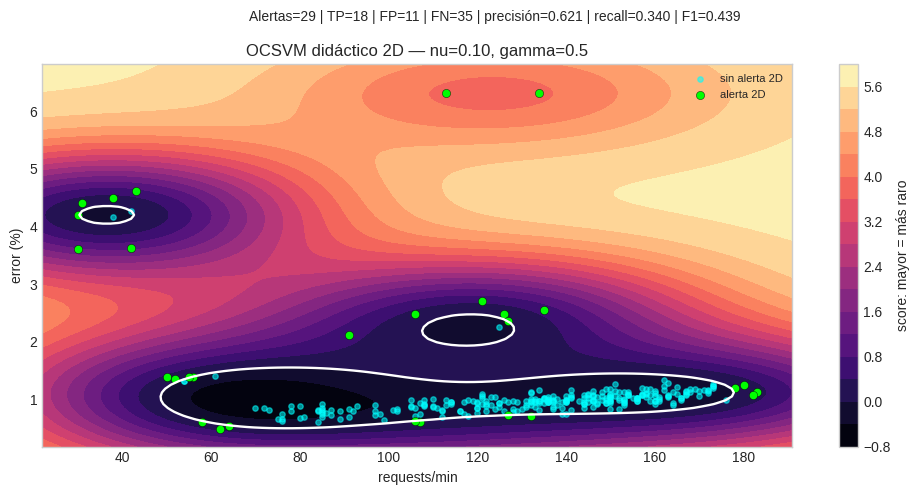

interactive(children=(Dropdown(description='Modelo', options=('OCSVM', 'IF'), value='OCSVM'), FloatSlider(valu…

In [65]:
scaler_mapa = StandardScaler().fit(data[['requests', 'error_rate']])
X_mapa = scaler_mapa.transform(data[['requests', 'error_rate']])
map_x, map_y = np.meshgrid(
    np.linspace(data.requests.min()-8, data.requests.max()+8, 100),
    np.linspace(max(0, data.error_rate.min()-.003), data.error_rate.max()+.005, 100))
grid_mapa = scaler_mapa.transform(pd.DataFrame({
    'requests': map_x.ravel(), 'error_rate': map_y.ravel()}))

def explorar_mapa(modelo='OCSVM', contamination=.10, nu=.10, gamma=.5):
    if modelo == 'IF':
        m = IsolationForest(n_estimators=300, max_samples=256,
                            contamination=contamination, random_state=SEED).fit(X_mapa)
        campo = -m.score_samples(grid_mapa)
        corte = -m.offset_
        detalle = f'contamination={contamination:.2f}'
    else:
        m = OneClassSVM(kernel='rbf', nu=nu, gamma=gamma).fit(X_mapa)
        campo = -m.decision_function(grid_mapa)
        corte = 0.
        detalle = f'nu={nu:.2f}, gamma={gamma:.3g}'
    flags = m.predict(X_mapa) == -1
    campo = campo.reshape(map_x.shape)
    fig, ax = plt.subplots(figsize=(10, 5))
    fondo = ax.contourf(map_x, 100*map_y, campo, levels=18, cmap='magma')
    if campo.min() < corte < campo.max():
        ax.contour(map_x, 100*map_y, campo, levels=[corte], colors='white', linewidths=1.7)
    ax.scatter(data.requests[~flags], 100*data.error_rate[~flags], c='cyan', s=15, alpha=.55, label='sin alerta 2D')
    ax.scatter(data.requests[flags], 100*data.error_rate[flags], c='lime', edgecolors='black', linewidths=.3, s=35, label='alerta 2D')
    ax.set(xlabel='requests/min', ylabel='error (%)', title=f'{modelo} didáctico 2D — {detalle}')
    ax.legend(fontsize=8)
    ax.grid(False)
    fig.colorbar(fondo, ax=ax, label='score: mayor = más raro')
    fig.suptitle(resumen_panel(flags), fontsize=10)
    fig.tight_layout()
    plt.show()

explorar_mapa()
if WIDGETS_AVAILABLE:
    widgets.interact(explorar_mapa,
        modelo=widgets.Dropdown(options=['OCSVM', 'IF'], description='Modelo'),
        contamination=slider_real(.10, .01, .30, .01, 'IF: contamination'),
        nu=slider_real(.10, .02, .30, .01, 'OCSVM: nu'),
        gamma=widgets.FloatLogSlider(value=.5, base=10, min=-2, max=1, step=.1, description='OCSVM: gamma', continuous_update=False))

### 11.5 Construcción de la frontera RBF

Con los **32 vectores de soporte** se reproduce la frontera del modelo 2D; al reducir la barra se omiten contribuciones y cambia la curva blanca. Una campana mide similitud con un vector, y la suma ponderada determina f(x). Esta barra explica el cálculo con gamma y nu fijos: usar menos términos no equivale a entrenar otro modelo ni a regularizarlo.


Con todos los vectores: diferencia máxima frente a sklearn = 4.44e-15


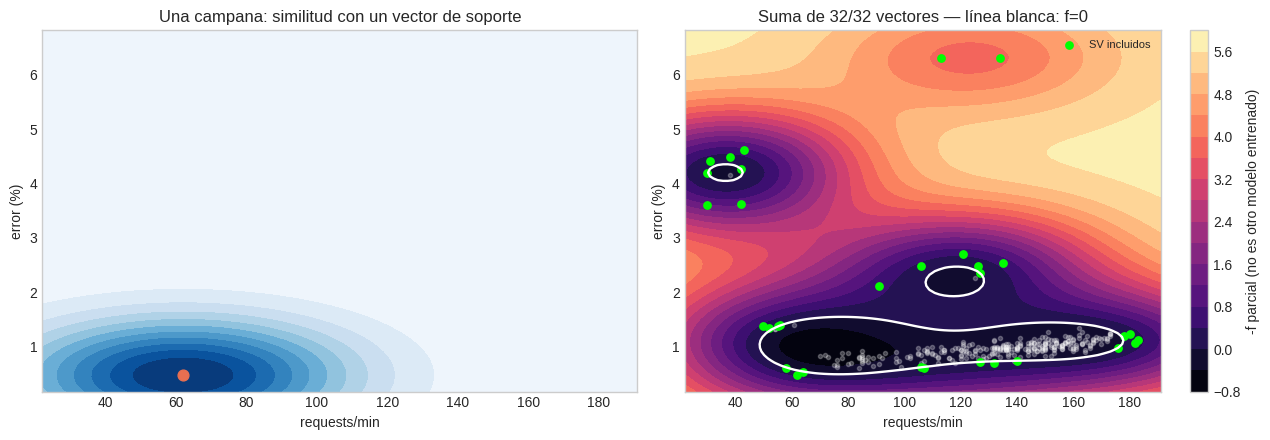

interactive(children=(IntSlider(value=32, continuous_update=False, description='Vectores SV', max=32, min=1), …

In [66]:
modelo_suma = OneClassSVM(kernel='rbf', nu=.10, gamma=.5).fit(X_mapa)
puntos_sv = modelo_suma.support_vectors_
pesos_sv = modelo_suma.dual_coef_.ravel()
orden_sv = np.argsort(-np.abs(pesos_sv))
rho_suma = float(modelo_suma.offset_[0])
# Cada columna contiene una campana centrada en un vector de soporte.
campanas = np.exp(-.5 * ((grid_mapa[:, None, :] - puntos_sv[None, :, :])**2).sum(axis=2))
sv_crudos = scaler_mapa.inverse_transform(puntos_sv)
error_suma_completa = np.max(np.abs(campanas @ pesos_sv - rho_suma - modelo_suma.decision_function(grid_mapa)))
assert error_suma_completa < 1e-7
print(f'Con todos los vectores: diferencia máxima frente a sklearn = {error_suma_completa:.2e}')

def explorar_suma(cantidad=1):
    usados = orden_sv[:cantidad]
    pendientes = orden_sv[cantidad:]
    parcial = (campanas[:, usados] @ pesos_sv[usados] - rho_suma).reshape(map_x.shape)
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
    axes[0].contourf(map_x, 100*map_y, campanas[:, orden_sv[0]].reshape(map_x.shape), levels=np.linspace(0, 1, 12), cmap='Blues')
    axes[0].scatter(sv_crudos[orden_sv[0], 0], 100*sv_crudos[orden_sv[0], 1], c=ORANGE, s=60)
    axes[0].set_title('Una campana: similitud con un vector de soporte')
    fondo = axes[1].contourf(map_x, 100*map_y, -parcial, levels=16, cmap='magma')
    if parcial.min() < 0 < parcial.max():
        axes[1].contour(map_x, 100*map_y, parcial, levels=[0], colors='white', linewidths=1.7)
    axes[1].scatter(data.requests, 100*data.error_rate, c='white', s=9, alpha=.25)
    axes[1].scatter(sv_crudos[usados, 0], 100*sv_crudos[usados, 1], c='lime', s=28, label='SV incluidos')
    if len(pendientes):
        axes[1].scatter(sv_crudos[pendientes, 0], 100*sv_crudos[pendientes, 1], c='cyan', marker='x', s=22, label='SV pendientes')
    axes[1].set_title(f'Suma de {cantidad}/{len(puntos_sv)} vectores — línea blanca: f=0')
    axes[1].legend(fontsize=8)
    fig.colorbar(fondo, ax=axes[1], label='-f parcial (no es otro modelo entrenado)')
    for ax in axes:
        ax.set(xlabel='requests/min', ylabel='error (%)')
        ax.grid(False)
    fig.tight_layout()
    plt.show()

explorar_suma(len(puntos_sv))
if WIDGETS_AVAILABLE:
    widgets.interact(explorar_suma, cantidad=widgets.IntSlider(
        value=len(puntos_sv), min=1, max=len(puntos_sv), step=1,
        description='Vectores SV', continuous_update=False))